# GoEmotions · Phân loại cảm xúc đa nhãn

**Nhóm 6 · HUFLIT · Báo cáo IEEE v8**

Chọn **Restart Kernel → Run All** trong bản dự án đầy đủ. Notebook có sẵn đầu ra và tính lại các bảng từ dữ liệu gốc hoặc điểm đã khóa. Phần A suy luận lại với mô hình đã fit. Phần B/C tái hiện điểm báo cáo từ kết quả đã lưu. Chương 2 có ví dụ tính tay; phần cuối kiểm các bảng mới của v8 bằng số đo thô và điểm dự đoán.


# Phần 1. Dữ liệu — Chương 3

# Khám phá dữ liệu GoEmotions cho phân loại cảm xúc đa nhãn

**Đầu ra:** số mẫu, phân bố đầy đủ 28 nhãn, 30 ví dụ có ID, kiểm tra chất lượng,
biểu đồ và báo cáo có thể chạy lại. Các kết quả được tính từ dữ liệu thật ở revision cố định.

**Cách học:** đọc phần giải thích → chạy ô code ngay bên dưới bằng `Shift+Enter` →
đối chiếu bảng/biểu đồ → đọc nhận xét. Có thể dùng **Restart Kernel and Run All Cells**.
Notebook có sẵn đầu ra; chạy lại các ô để kiểm chứng trên máy mình.

**Phạm vi:** EDA cho GoEmotions: phân bố nhãn, chất lượng dữ liệu, multi-hot,
mất cân bằng, độ dài và đồng xuất hiện. Xem phần Notebook chính trong README ở gốc dự án và bài GoEmotions
ACL 2020 để hiểu vị trí của bước này trong đồ án.
Phần EDA này chỉ mô tả dữ liệu; kết quả mô hình nằm ở các phần sau.

**Ngôn ngữ và công cụ:** Python 3.12/3.13; pandas/NumPy để đếm; PyArrow đọc Parquet;
Matplotlib/Seaborn vẽ hình; Hugging Face Tokenizers đo token; Jupyter để theo dõi từng bước.
Chạy CPU, không cần GPU, khóa API hay tải trọng số mô hình.

**Dữ liệu tiếng Anh:** bình luận Reddit, 27 cảm xúc + `neutral`. Diễn giải tiếng Việt
chỉ giúp học; không dịch hay sửa văn bản đầu vào, không thay tên nhãn chuẩn.

## Lộ trình

1. Môi trường và đường dẫn
2. Tải và kiểm chứng dữ liệu
3. Cấu trúc và mapping nhãn
4. Chất lượng và số mẫu
5. Mã hóa đa nhãn
6. Phân bố 28 nhãn
7. Mất cân bằng và nhãn hiếm
8. Số nhãn trên mỗi mẫu
9. Neutral và đồng xuất hiện
10. Trùng lặp trong/giữa các split
11. Độ dài văn bản
12. Độ dài theo ba tokenizer
13. Ba mươi ví dụ có thể truy vết
14. Đối chiếu snapshot
15. Xuất dữ liệu và báo cáo
16. Kết luận, giới hạn và câu hỏi tự kiểm tra

**Quy tắc sử dụng split:** thống kê test chỉ mô tả bộ dữ liệu, không dùng để chọn mô hình,
ngưỡng, nhãn hiếm hoặc độ dài cắt. Phân tích sâu, ví dụ minh họa và đồng xuất hiện dùng train.
Giữ nguyên split chính; không tự ý xóa bản ghi trùng hay ép mỗi mẫu về một nhãn.

**Đối chiếu:** Chương 3 báo cáo IEEE v8; slide 4–6 PPT. Số liệu được tính từ snapshot chính thức, tokenizer lấy đúng revision của lượt huấn luyện.

## Bước 1 — Chuẩn bị môi trường

Ở terminal tại thư mục dự án, chạy `python -m pip install -e ".[eda,transformers,notebooks]"`, rồi
`python -m jupyterlab`. Chọn kernel của đúng môi trường đã cài thư viện.
Nếu dùng Colab: tải cả repo lên `/content/goemotions-multilabel-classification`,
chuyển thư mục bằng `%cd /content/goemotions-multilabel-classification` và cài bằng
`%pip install -e ".[eda,transformers,notebooks]"`, sau đó khởi động lại runtime nếu được yêu cầu.
Chỉ tải riêng file ipynb sẽ thiếu `src/datasets/goemotions.py` và cấu hình tokenizer.

Ô dưới tìm thư mục gốc, tạo thư mục output và ghi lại phiên bản thật.
Không cần thay đường dẫn tuyệt đối của máy người viết.

In [1]:
from pathlib import Path
import sys, json, platform, importlib.metadata, re
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/datasets/goemotions.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Hãy mở notebook trong repo đầy đủ, hoặc chuyển cwd đến gốc repo.')
sys.path.insert(0, str(ROOT))
from src.notebook_support import artifacts_root
ARTIFACTS = artifacts_root()
from src.datasets.goemotions import load_goemotions, multi_hot, download, sha256, SPLITS, REVISION
SEED = 42
TABLES, FIGURES = ROOT / 'reports/tables', ROOT / 'reports/figures'
for folder in [TABLES, FIGURES, ROOT / 'data/processed']:
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 130)
sns.set_theme(style='whitegrid', font='DejaVu Sans', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180})

def save_table(df, name):
    df.to_csv(TABLES / f'{name}.csv', index=False, encoding='utf-8-sig')

def finish_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close()

packages = ['numpy','pandas','pyarrow','matplotlib','seaborn','tokenizers',
            'nbformat','nbclient','nbconvert','ipykernel','jupyterlab','tabulate']
environment = {'python': platform.python_version(), 'platform': platform.platform(),
               'packages': {p: importlib.metadata.version(p) for p in packages}}
(ROOT / 'reports/environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
print('Thư mục dự án:', ROOT)
display(pd.Series(environment['packages'], name='version').to_frame())

Thư mục dự án: D:\DoAn\Đồ án NLP\GoEmotions_IEEE_v8_20261122\github_verify


,version
numpy,2.3.5
pandas,2.3.3
pyarrow,21.0.0
matplotlib,3.10.6
seaborn,0.13.2
tokenizers,0.22.2
nbformat,5.10.4
nbclient,0.10.2
nbconvert,7.16.6
ipykernel,6.31.0


## Bước 2 — Tải đúng phiên bản và kiểm tra dấu vân tay

Nguồn: [GoEmotions trên Hugging Face](https://huggingface.co/datasets/google-research-datasets/go_emotions).
Revision cố định: `add492243ff905527e67aeb8b80c082af02207c3`, cấu hình `simplified`.
Ba file tổng cộng khoảng 3,5 MB. Lần sau đọc cache cục bộ; luôn kiểm SHA-256.

`load_goemotions` tải file, đối chiếu hash cố định trong `src/datasets/goemotions.py`, đọc schema,
kiểm tra số dòng và bảo đảm mapping nhãn giống nhau giữa ba split.
Sai hash/schema sẽ dừng, tránh âm thầm phân tích một phiên bản khác.
Manifest lưu URL, revision, thời điểm kiểm chứng, dung lượng, hash đầy đủ và số dòng.

In [2]:
frames, label_names, manifest = load_goemotions(ARTIFACTS, write_metadata=False)
display(pd.DataFrame(manifest['files'])[['split','rows','bytes','sha256']])
print('Revision:', manifest['revision'])
print('Tổng số mẫu:', sum(map(len, frames.values())))

,split,rows,bytes,sha256
0,train,43410,2767678,b7d74279616ae7c9b8374ab62ea9f9d6504d36a577bb17f745d720dc2b0d4e76
1,validation,5426,350063,d46ad5633c4fa41829d22d549743a7bf858d94129536a02af7280c281db5e63a
2,test,5427,346630,fd0953e535ba2569edc6a1daaa1133f8e4b9071691d540c9bab812fda132bc26


Revision: add492243ff905527e67aeb8b80c082af02207c3
Tổng số mẫu: 54263


## Bước 3 — Hiểu cấu trúc dữ liệu và 28 nhãn

Mỗi dòng là một bình luận đã có tập nhãn: `id` là mã bình luận, `text` là nguyên văn,
`labels` là danh sách ID nhãn (đánh số từ 0). Đây không phải bảng từng lượt gán nhãn
của từng annotator trong cấu hình `raw`.

**Đa lớp** thường chọn đúng một lớp; **đa nhãn** cho phép nhiều nhãn cùng bằng 1.
Ví dụ `[8, 20]` tương ứng `desire` và `optimism`, không phải lớp số 820.
Mapping phải lấy từ metadata, không sắp tên theo tần suất rồi dùng thứ tự đó để mã hóa.

In [3]:
vi_names = ['ngưỡng mộ','thích thú','tức giận','khó chịu','tán thành','quan tâm',
            'bối rối','tò mò','mong muốn','thất vọng','không tán thành','ghê tởm',
            'ngượng ngùng','hào hứng','sợ hãi','biết ơn','đau buồn sâu sắc','vui vẻ',
            'yêu thương','lo lắng hồi hộp','lạc quan','tự hào','nhận ra','nhẹ nhõm',
            'hối hận','buồn bã','ngạc nhiên','trung tính']
label_mapping = pd.DataFrame({'label_id': range(28), 'label': label_names,
                              'dien_giai_vi': vi_names})
save_table(label_mapping, 'label_mapping')
display(label_mapping)
display(frames['train'].head(3))
display(frames['train'].dtypes.to_frame('dtype'))

,label_id,label,dien_giai_vi
0,0,admiration,ngưỡng mộ
1,1,amusement,thích thú
2,2,anger,tức giận
3,3,annoyance,khó chịu
4,4,approval,tán thành
5,5,caring,quan tâm
6,6,confusion,bối rối
7,7,curiosity,tò mò
8,8,desire,mong muốn
9,9,disappointment,thất vọng


,text,labels,id
0,My favourite food is anything I didn't have to cook myself.,[27],eebbqej
1,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead",[27],ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj


,dtype
text,object
labels,object
id,object


## Bước 4 — Số mẫu và chất lượng dữ liệu

Đếm thiếu giá trị, text rỗng sau `strip`, nhãn rỗng, nhãn trùng trong một mẫu,
nhãn ngoài miền 0–27 và ID lặp. Text chỉ được strip trong phép kiểm tra;
cột `text` gốc được giữ nguyên. `duplicate_*_extra_rows` đếm các dòng dư sau
bản ghi đầu tiên, khác với số nhóm trùng hoặc tổng số dòng tham gia nhóm trùng.

,split,n_samples,missing_text,missing_id,blank_text,empty_labels,repeated_labels,invalid_labels,unique_ids,unique_texts,duplicate_id_extra_rows,duplicate_text_extra_rows
0,train,43410,0,0,0,0,0,0,43410,43227,0,183
1,validation,5426,0,0,0,0,0,0,5426,5423,0,3
2,test,5427,0,0,0,0,0,0,5427,5421,0,6


,split,n_samples,percent_all_samples
0,train,43410,79.9993
1,validation,5426,9.9994
2,test,5427,10.0013


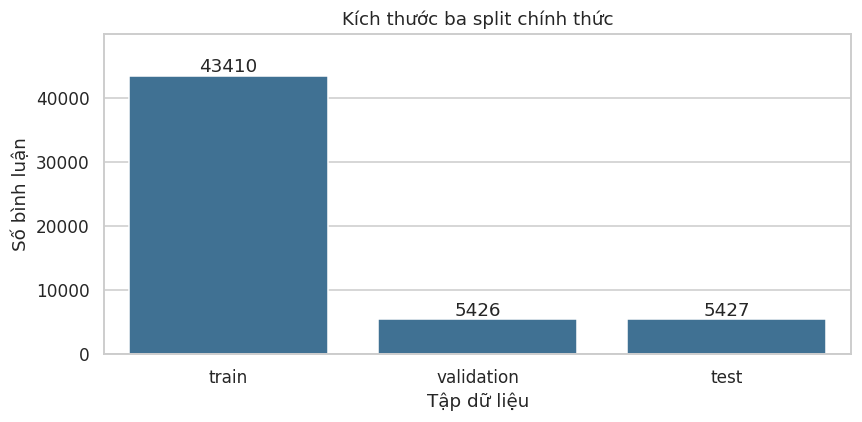

In [4]:
quality_rows = []
for split, df in frames.items():
    quality_rows.append({
        'split': split, 'n_samples': len(df),
        'missing_text': int(df.text.isna().sum()), 'missing_id': int(df.id.isna().sum()),
        'blank_text': int(df.text.str.strip().eq('').sum()),
        'empty_labels': int(df.labels.map(len).eq(0).sum()),
        'repeated_labels': int(df.labels.map(lambda v: len(v) != len(set(v))).sum()),
        'invalid_labels': int(df.labels.map(lambda v: any(not 0 <= j < 28 for j in v)).sum()),
        'unique_ids': df.id.nunique(), 'unique_texts': df.text.nunique(),
        'duplicate_id_extra_rows': int(df.id.duplicated().sum()),
        'duplicate_text_extra_rows': int(df.text.duplicated().sum())})
quality = pd.DataFrame(quality_rows)
save_table(quality, 'data_quality')
display(quality)
checks = ['missing_text','missing_id','blank_text','empty_labels','repeated_labels',
          'invalid_labels','duplicate_id_extra_rows']
assert quality[checks].to_numpy().sum() == 0, 'Có bất thường cần xem trước khi phân tích.'
split_sizes = quality[['split','n_samples']].copy()
split_sizes['percent_all_samples'] = split_sizes.n_samples / split_sizes.n_samples.sum() * 100
display(split_sizes.round(4))
save_table(split_sizes, 'split_sizes')
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=split_sizes, x='split', y='n_samples', color='#3274A1')
ax.bar_label(ax.containers[0], fmt='%d')
ax.set(xlabel='Tập dữ liệu', ylabel='Số bình luận', title='Kích thước ba split chính thức')
ax.set_ylim(0, split_sizes.n_samples.max() * 1.15)
finish_figure('01_split_sizes')

**Cách đọc:** tổng `simplified` phải là 54.263, khác khoảng 58 nghìn bình luận
được mô tả cho bộ gốc trong [bài báo ACL 2020](https://aclanthology.org/2020.acl-main.372/).
Khoảng 80%/10%/10% là split do nguồn cung cấp, không phải phép chia ngẫu nhiên mới của nhóm.

## Bước 5 — Mã hóa multi-hot và kiểm chứng

Tạo `Y` kích thước N × 28: `Y[i, j] = 1` khi mẫu i có nhãn j, còn lại bằng 0.
Tổng một hàng là số nhãn của mẫu; tổng một cột là số mẫu mang nhãn đó (support).
EDA lưu `uint8` để tiết kiệm bộ nhớ; khi huấn luyện BCE cần chuyển nhãn sang float.

In [5]:
Y = {split: multi_hot(df.labels.tolist()) for split, df in frames.items()}
for split, matrix in Y.items():
    assert matrix.shape == (len(frames[split]), 28)
    assert np.array_equal(matrix.sum(axis=1), frames[split].labels.map(len).to_numpy())
    print(split, matrix.shape, matrix.dtype)
example_i = next(i for i, labels in enumerate(frames['train'].labels) if len(labels) > 1)
display(frames['train'].iloc[[example_i]])
display(pd.DataFrame(Y['train'][[example_i]], columns=label_names))
print('Nhãn được giải mã:', [label_names[j] for j in np.flatnonzero(Y['train'][example_i])])

train (43410, 28) uint8
validation (5426, 28) uint8
test (5427, 28) uint8


,text,labels,id
7,We need more boards and to create a bit more space for [NAME]. Then we’ll be good.,"[8, 20]",ef4qmod


,admiration,amusement,anger,annoyance,approval,caring,confusion,curiosity,desire,disappointment,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,0,0,0,0,0,0,0,0,1,0,...,0,0,1,0,0,0,0,0,0,0


Nhãn được giải mã: ['desire', 'optimism']


## Bước 6 — Phân bố đầy đủ 28 nhãn

Với nhãn j và split s: `support = sum(Y_s[:, j])`,
`prevalence (%) = 100 × support / số mẫu của split`.
Một mẫu đa nhãn được tính vào nhiều cột, nên **tổng tỷ lệ có thể vượt 100%**.
`share_of_assignments` có mẫu số là tổng lượt gán nhãn, là một đại lượng khác.
Notebook xuất cả hai, nhưng so sánh mức phổ biến giữa split bằng prevalence.

,label_id,label,train_count,validation_count,test_count,total_count,train_prevalence_pct
0,0,admiration,4130,488,504,5122,9.514
1,1,amusement,2328,303,264,2895,5.363
2,2,anger,1567,195,198,1960,3.610
3,3,annoyance,2470,303,320,3093,5.690
4,4,approval,2939,397,351,3687,6.770
5,5,caring,1087,153,135,1375,2.504
6,6,confusion,1368,152,153,1673,3.151
7,7,curiosity,2191,248,284,2723,5.047
8,8,desire,641,77,83,801,1.477
9,9,disappointment,1269,163,151,1583,2.923


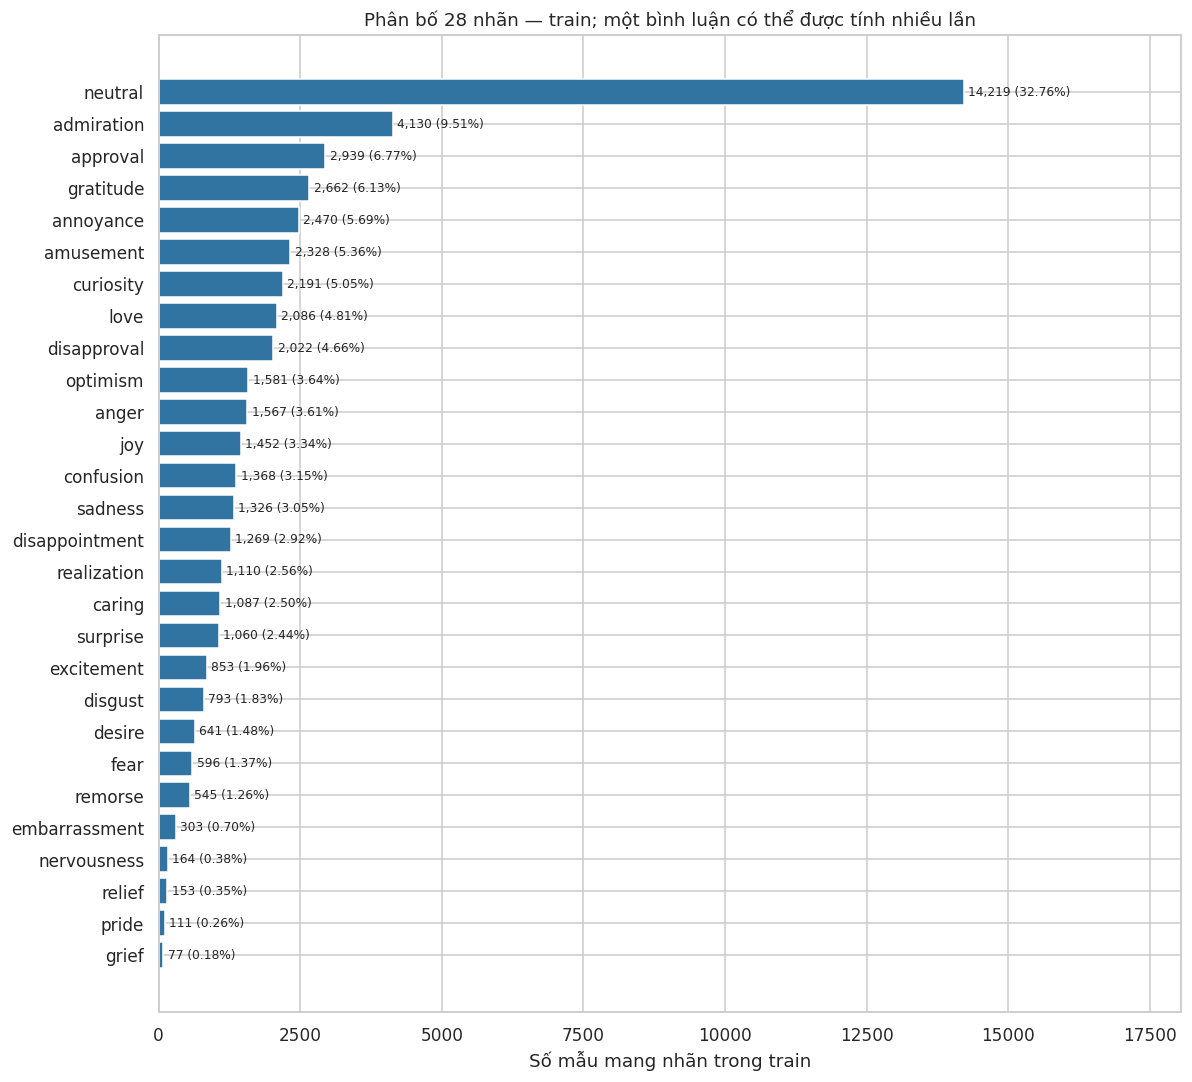

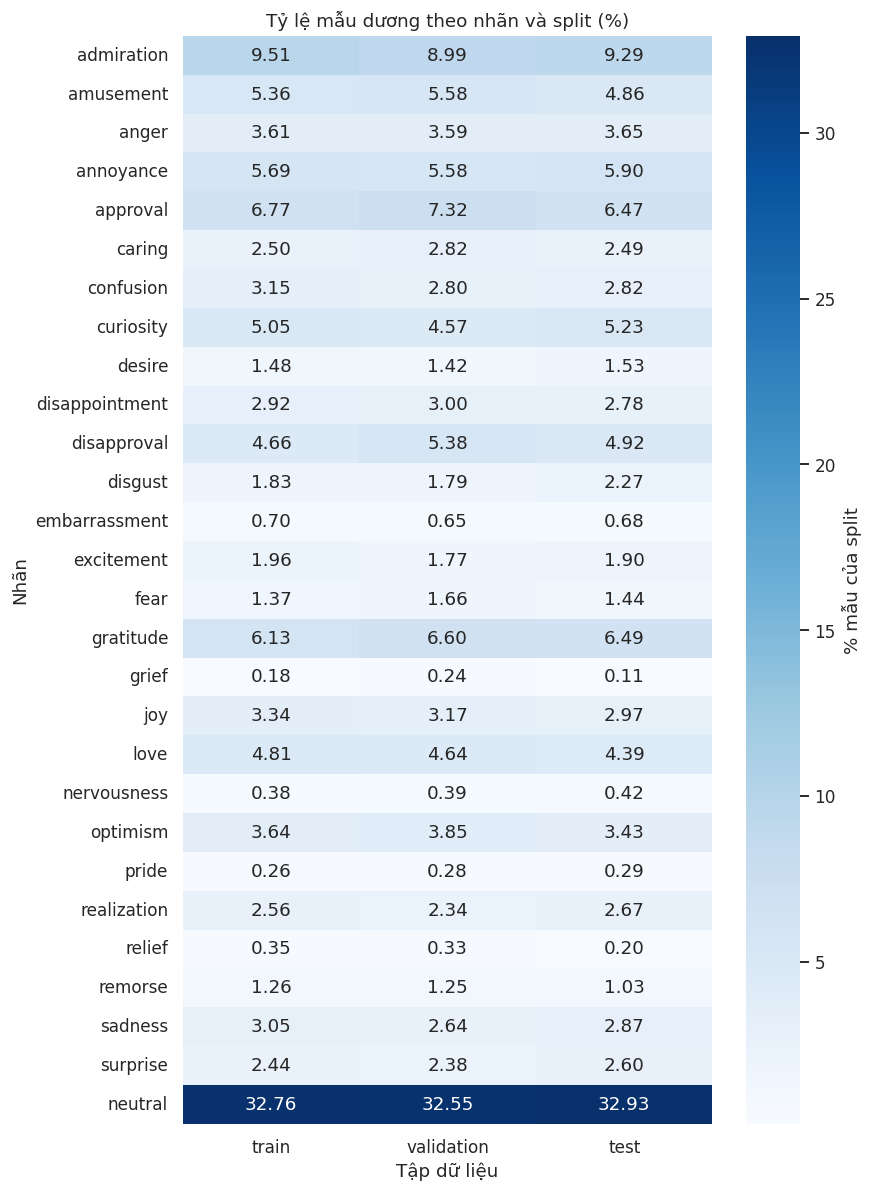

In [6]:
label_stats = label_mapping.copy()
for split in SPLITS:
    counts = Y[split].sum(axis=0).astype(int)
    label_stats[f'{split}_count'] = counts
    label_stats[f'{split}_prevalence_pct'] = counts / len(frames[split]) * 100
label_stats['total_count'] = label_stats[[f'{s}_count' for s in SPLITS]].sum(axis=1)
label_stats['total_prevalence_pct'] = label_stats.total_count / sum(map(len, frames.values())) * 100
label_stats['train_share_of_assignments_pct'] = label_stats.train_count / label_stats.train_count.sum() * 100
save_table(label_stats, 'label_distribution')
display(label_stats[['label_id','label','train_count','validation_count','test_count',
                     'total_count','train_prevalence_pct']].round(3))
ordered = label_stats.sort_values('train_count', ascending=True)
fig, ax = plt.subplots(figsize=(11, 10))
ax.barh(ordered.label, ordered.train_count, color='#3274A1')
for i, (_, row) in enumerate(ordered.iterrows()):
    ax.text(row.train_count + 80, i, f'{row.train_count:,} ({row.train_prevalence_pct:.2f}%)', va='center', fontsize=8)
ax.set(xlim=(0, ordered.train_count.max()*1.27), xlabel='Số mẫu mang nhãn trong train',
       ylabel='', title='Phân bố 28 nhãn — train; một bình luận có thể được tính nhiều lần')
finish_figure('02_label_distribution_train')
prevalence = label_stats.set_index('label')[[f'{s}_prevalence_pct' for s in SPLITS]]
prevalence.columns = list(SPLITS)
plt.figure(figsize=(8, 11))
sns.heatmap(prevalence, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': '% mẫu của split'})
plt.title('Tỷ lệ mẫu dương theo nhãn và split (%)')
plt.xlabel('Tập dữ liệu'); plt.ylabel('Nhãn')
finish_figure('03_prevalence_by_split')

## Bước 7 — Mất cân bằng và năm nhãn hiếm

Năm nhãn hiếm được xác định **chỉ bằng train**, sắp theo support tăng dần.
Tỷ số `max support / min support` mô tả độ mất cân bằng nhưng không đo chất lượng mô hình.
Xem thêm tỷ số khi bỏ neutral để thấy sự chênh lệch giữa riêng 27 cảm xúc.

In [7]:
rare = label_stats.sort_values(['train_count','label_id']).head(5).copy()
rare_names = rare.label.tolist()
imbalance_ratio = label_stats.train_count.max() / label_stats.train_count.min()
emotions_only = label_stats[label_stats.label != 'neutral']
emotion_ratio = emotions_only.train_count.max() / emotions_only.train_count.min()
display(rare[['label','train_count','validation_count','test_count','train_prevalence_pct']].round(4))
save_table(rare, 'rare_labels_train_defined')
print(f'Tỷ số lớn nhất/nhỏ nhất (28 nhãn): {imbalance_ratio:.2f} lần')
print(f'Tỷ số lớn nhất/nhỏ nhất (27 cảm xúc): {emotion_ratio:.2f} lần')
display(Markdown('**Nhận xét:** ' + ', '.join(rare_names) +
    ' là 5 nhãn ít mẫu nhất trên train. Số mẫu ít làm việc học và đo F1 từng nhãn kém ổn định. '
    'Theo kế hoạch nhóm, cần báo Macro-F1 cùng Micro-F1 và support từng nhãn; '
    'mọi trọng số lớp phải tính trên train, mọi ngưỡng phải chọn trên validation.'))

,label,train_count,validation_count,test_count,train_prevalence_pct
16,grief,77,13,6,0.1774
21,pride,111,15,16,0.2557
23,relief,153,18,11,0.3525
19,nervousness,164,21,23,0.3778
12,embarrassment,303,35,37,0.6980


Tỷ số lớn nhất/nhỏ nhất (28 nhãn): 184.66 lần
Tỷ số lớn nhất/nhỏ nhất (27 cảm xúc): 53.64 lần


**Nhận xét:** grief, pride, relief, nervousness, embarrassment là 5 nhãn ít mẫu nhất trên train. Số mẫu ít làm việc học và đo F1 từng nhãn kém ổn định. Theo kế hoạch nhóm, cần báo Macro-F1 cùng Micro-F1 và support từng nhãn; mọi trọng số lớp phải tính trên train, mọi ngưỡng phải chọn trên validation.

## Bước 8 — Một mẫu có bao nhiêu nhãn

**Cardinality** = tổng lượt gán nhãn / số mẫu, tức số nhãn trung bình trên một bình luận.
**Density** = cardinality / 28, tức tỷ lệ ô bằng 1 trong ma trận Y.
**Tỷ lệ đa nhãn** = số mẫu có ≥2 nhãn / số mẫu. Ba đại lượng này không đồng nghĩa.

,split,n_samples,label_assignments,one_label,two_labels,three_or_more,multi_label_samples,multi_label_pct,cardinality,density,max_labels
0,train,43410,51103,36308,6541,561,7102,16.36029,1.17722,0.04204,5
1,validation,5426,6380,4548,809,69,878,16.18135,1.17582,0.04199,4
2,test,5427,6329,4590,774,63,837,15.42289,1.16621,0.04165,4


,split,n_labels,n_samples,percent
0,train,1,36308,83.640
1,train,2,6541,15.068
2,train,3,532,1.226
3,train,4,28,0.065
4,train,5,1,0.002
5,validation,1,4548,83.819
6,validation,2,809,14.910
7,validation,3,62,1.143
8,validation,4,7,0.129
9,test,1,4590,84.577


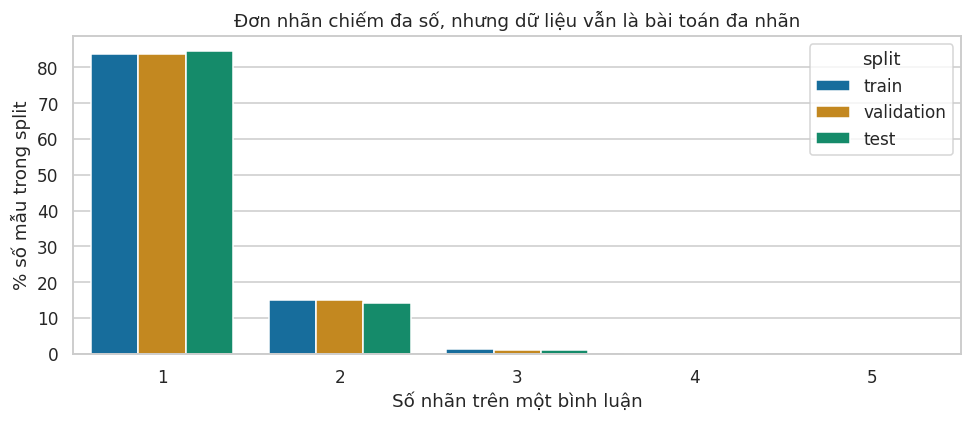

In [8]:
multi_rows, cardinality_rows = [], []
for split, df in frames.items():
    k = df.labels.map(len)
    multi_rows.append({'split': split, 'n_samples': len(df), 'label_assignments': int(k.sum()),
                      'one_label': int((k == 1).sum()), 'two_labels': int((k == 2).sum()),
                      'three_or_more': int((k >= 3).sum()), 'multi_label_samples': int((k >= 2).sum()),
                      'multi_label_pct': (k >= 2).mean()*100, 'cardinality': k.mean(),
                      'density': k.mean()/28, 'max_labels': int(k.max())})
    for n, count in k.value_counts().sort_index().items():
        cardinality_rows.append({'split': split, 'n_labels': n, 'n_samples': count, 'percent': count/len(df)*100})
multi_stats = pd.DataFrame(multi_rows)
cardinality_dist = pd.DataFrame(cardinality_rows)
display(multi_stats.round(5)); display(cardinality_dist.round(3))
save_table(multi_stats, 'multilabel_summary'); save_table(cardinality_dist, 'labels_per_sample')
plt.figure(figsize=(9, 4))
sns.barplot(data=cardinality_dist, x='n_labels', y='percent', hue='split')
plt.xlabel('Số nhãn trên một bình luận'); plt.ylabel('% số mẫu trong split')
plt.title('Đơn nhãn chiếm đa số, nhưng dữ liệu vẫn là bài toán đa nhãn')
finish_figure('04_labels_per_sample')

## Bước 9 — Neutral và các nhãn cùng xuất hiện

Tách `neutral` đứng một mình khỏi `neutral` cùng nhãn khác. Không tự đặt quy tắc
“có neutral thì xóa mọi cảm xúc”, vì sẽ thay ground truth của dữ liệu.

Với train, `C = Y.T @ Y` đếm số mẫu cùng có hai nhãn. Đường chéo là support,
không phải cặp hai nhãn khác nhau. Chuyển sang **int64 trước khi nhân** để tránh
tràn số `uint8`. Heatmap dùng log(1 + count) để thấy cả cặp phổ biến lẫn hiếm.
Jaccard = giao / hợp, nằm trong [0,1]; không phải quan hệ nhân quả hay độ giống nghĩa.

,split,neutral_total,neutral_only,neutral_with_other,neutral_with_other_pct_all
0,train,14219,12823,1396,3.216
1,validation,1766,1592,174,3.207
2,test,1787,1606,181,3.335


,label_a,label_b,count,percent_train,jaccard
14,admiration,gratitude,279,0.6427,0.0428
53,anger,annoyance,269,0.6197,0.0714
3,admiration,approval,246,0.5667,0.0361
147,confusion,curiosity,212,0.4884,0.0633
124,approval,neutral,202,0.4653,0.0119
17,admiration,love,192,0.4423,0.0319
84,annoyance,disapproval,178,0.4100,0.0413
222,disappointment,sadness,133,0.3064,0.0540
101,annoyance,neutral,132,0.3041,0.0080
16,admiration,joy,126,0.2903,0.0231


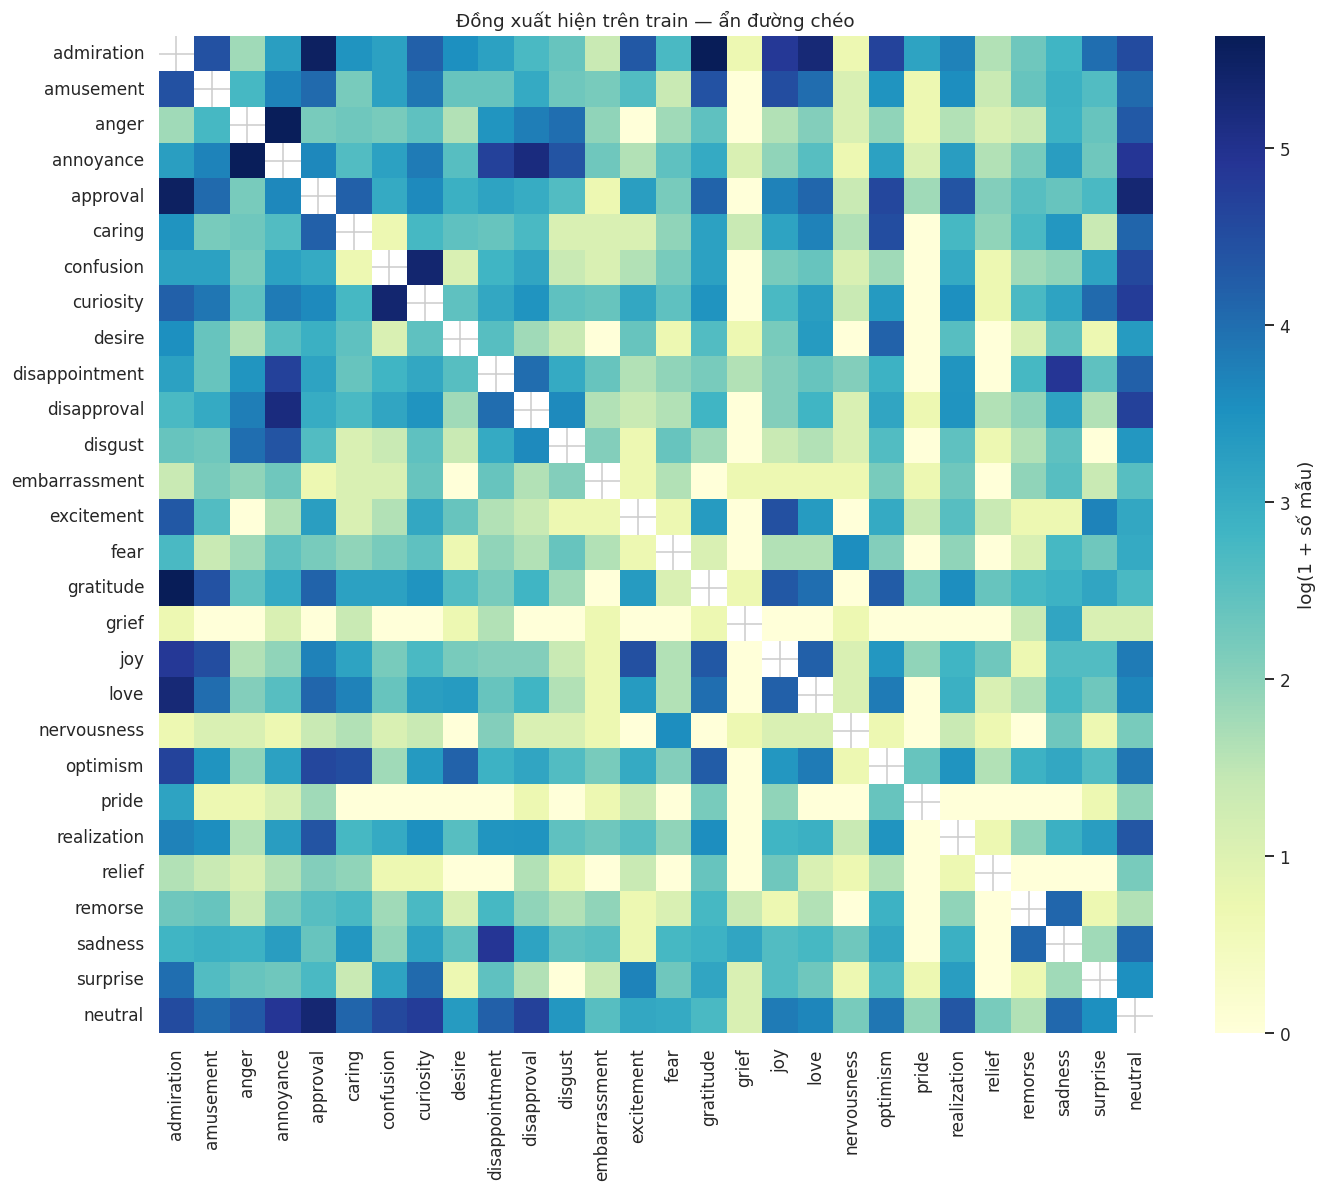

In [9]:
neutral_id = label_names.index('neutral')
neutral_rows = []
for split, matrix in Y.items():
    has_neutral = matrix[:, neutral_id].astype(bool)
    is_multi = matrix.sum(axis=1) > 1
    neutral_rows.append({'split': split, 'neutral_total': int(has_neutral.sum()),
        'neutral_only': int((has_neutral & ~is_multi).sum()),
        'neutral_with_other': int((has_neutral & is_multi).sum()),
        'neutral_with_other_pct_all': (has_neutral & is_multi).mean()*100})
neutral_stats = pd.DataFrame(neutral_rows)
display(neutral_stats.round(3)); save_table(neutral_stats, 'neutral_summary')
y64 = Y['train'].astype(np.int64)
co = y64.T @ y64
support = np.diag(co)
pairs = pd.DataFrame([
    {'label_a': label_names[a], 'label_b': label_names[b], 'count': int(co[a,b]),
     'percent_train': co[a,b]/len(y64)*100,
     'jaccard': co[a,b]/(support[a]+support[b]-co[a,b])}
    for a,b in combinations(range(28), 2)
]).sort_values(['count','label_a','label_b'], ascending=[False, True, True])
display(pairs.head(15).round(4)); save_table(pairs, 'label_cooccurrence_pairs_train')
pd.DataFrame(co, index=label_names, columns=label_names).to_csv(TABLES/'cooccurrence_matrix_train.csv', encoding='utf-8-sig')
plt.figure(figsize=(13, 11))
sns.heatmap(np.log1p(co), mask=np.eye(28, dtype=bool), cmap='YlGnBu',
            xticklabels=label_names, yticklabels=label_names, cbar_kws={'label':'log(1 + số mẫu)'})
plt.title('Đồng xuất hiện trên train — ẩn đường chéo'); plt.xticks(rotation=90); plt.yticks(rotation=0)
finish_figure('05_cooccurrence_train')

## Bước 10 — Kiểm tra trùng lặp và nguy cơ rò rỉ

Kiểm tra ID giao nhau giữa các split và text **trùng nguyên chuỗi**, phân biệt:
(1) số chuỗi khác nhau bị trùng, (2) số dòng bị ảnh hưởng ở mỗi phía.
Hai dòng có text giống nhau vẫn có thể có ID và nhãn khác nhau.

Kiểm tra thêm chuẩn hóa nhẹ `casefold + gộp khoảng trắng` là phép chẩn đoán riêng,
không phải bằng chứng hai bản ghi có cùng nguồn gốc, không thay đổi dữ liệu gốc.
Không đủ metadata trong simplified để kết luận trùng tác giả hoặc cùng cuộc hội thoại.

In [10]:
overlap_rows = []
for a,b in combinations(SPLITS, 2):
    left, right = frames[a], frames[b]
    id_overlap = set(left.id) & set(right.id)
    exact = set(left.text) & set(right.text)
    normalize = lambda s: s.str.casefold().str.replace(r'\s+', ' ', regex=True).str.strip()
    ln, rn = normalize(left.text), normalize(right.text)
    norm_overlap = set(ln) & set(rn)
    overlap_rows.append({'left_split': a, 'right_split': b, 'shared_ids': len(id_overlap),
        'shared_exact_texts': len(exact), 'left_rows_exact': int(left.text.isin(exact).sum()),
        'right_rows_exact': int(right.text.isin(exact).sum()),
        'shared_normalized_texts': len(norm_overlap), 'right_rows_normalized': int(rn.isin(norm_overlap).sum())})
overlap = pd.DataFrame(overlap_rows)
assert overlap.shared_ids.sum() == 0
display(overlap); save_table(overlap, 'cross_split_overlap')
duplicate_rows = []
for split, df in frames.items():
    temp = df.assign(label_set=df.labels.map(lambda x: tuple(sorted(x))))
    groups = temp.groupby('text').agg(n_rows=('id','size'), n_label_sets=('label_set','nunique'))
    duplicate_rows.append({'split': split, 'duplicate_text_groups': int((groups.n_rows > 1).sum()),
        'rows_in_duplicate_groups': int(groups.loc[groups.n_rows > 1,'n_rows'].sum()),
        'duplicate_extra_rows': len(df)-len(groups),
        'duplicate_groups_with_different_labels': int(((groups.n_rows > 1)&(groups.n_label_sets > 1)).sum())})
duplicates = pd.DataFrame(duplicate_rows)
display(duplicates); save_table(duplicates, 'within_split_duplicates')
test_not_in_train = ~frames['test'].text.isin(set(frames['train'].text))
clean_test_ids = frames['test'].loc[test_not_in_train, ['id']]
save_table(clean_test_ids, 'test_ids_without_exact_train_overlap')
print('Test chính giữ nguyên:', len(frames['test']))
print('Test phân tích độ nhạy, loại text trùng train:', len(clean_test_ids))
print('Danh sách trên chưa loại text trùng validation; không gọi đây là tập hoàn toàn độc lập.')

,left_split,right_split,shared_ids,shared_exact_texts,left_rows_exact,right_rows_exact,shared_normalized_texts,right_rows_normalized
0,train,validation,0,41,84,43,46,49
1,train,test,0,32,79,37,37,42
2,validation,test,0,10,10,13,11,14


,split,duplicate_text_groups,rows_in_duplicate_groups,duplicate_extra_rows,duplicate_groups_with_different_labels
0,train,118,301,183,58
1,validation,2,5,3,1
2,test,5,11,6,1


Test chính giữ nguyên: 5427
Test phân tích độ nhạy, loại text trùng train: 5390
Danh sách trên chưa loại text trùng validation; không gọi đây là tập hoàn toàn độc lập.


## Bước 11 — Độ dài văn bản

Đếm ký tự bằng `len(text)` (Unicode code points) và “từ” bằng `text.split()`
(đơn vị cách nhau bởi khoảng trắng). Đây là hai phép mô tả đơn giản,
**không phải số subword token** của BERT/RoBERTa.
P50 là trung vị; P95/P99 cho biết vùng đuôi của phân bố, không chứng minh rằng
chọn đúng mốc đó là cấu hình tối ưu.

,split,measure,min,mean,std,p50,p90,p95,p99,max
0,train,n_chars,2,68.40,36.72,65.0,120.0,131.00,151.0,703
1,train,n_words_whitespace,1,12.84,6.70,12.0,22.0,24.00,27.0,33
2,validation,n_chars,5,68.24,36.91,64.0,121.0,133.00,152.0,187
3,validation,n_words_whitespace,1,12.79,6.74,12.0,23.0,24.75,27.0,30
4,test,n_chars,5,67.82,36.32,65.0,119.0,132.00,148.0,184
5,test,n_words_whitespace,1,12.73,6.67,12.0,22.0,24.00,27.0,32


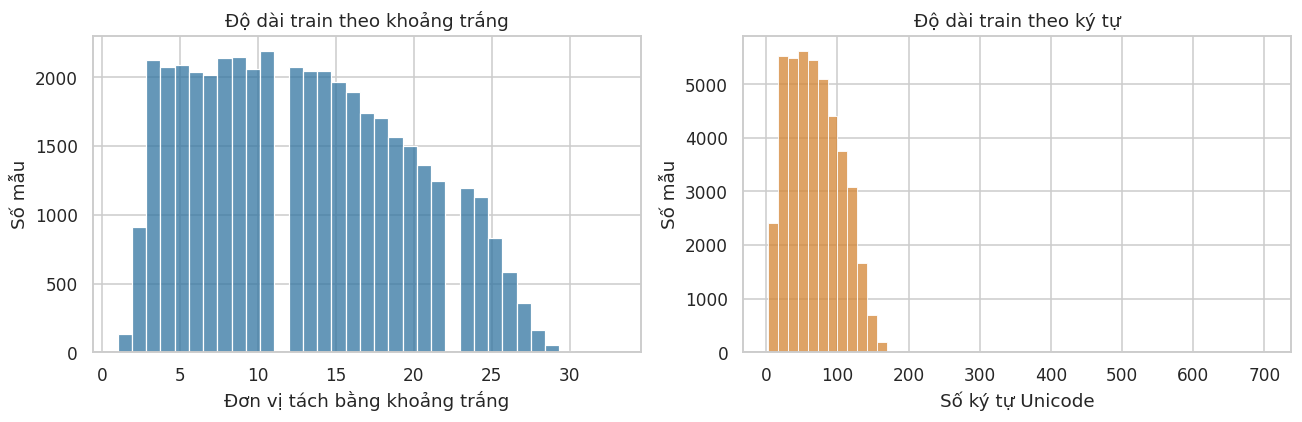

**Lưu ý:** giữ dấu câu, chữ hoa, emoji và phủ định trong dữ liệu gốc. Chưa chọn `max_length` từ số từ; bước kế tiếp đo đúng tokenizer.

In [11]:
length_frames, length_rows = {}, []
for split, df in frames.items():
    lengths = pd.DataFrame({'id': df.id, 'n_chars': df.text.str.len(),
                             'n_words_whitespace': df.text.str.split().str.len()})
    length_frames[split] = lengths
    for feature in ['n_chars','n_words_whitespace']:
        values = lengths[feature]
        length_rows.append({'split': split, 'measure': feature, 'min': values.min(),
            'mean': values.mean(), 'std': values.std(), 'p50': values.quantile(.5),
            'p90': values.quantile(.9), 'p95': values.quantile(.95),
            'p99': values.quantile(.99), 'max': values.max()})
length_summary = pd.DataFrame(length_rows)
display(length_summary.round(2)); save_table(length_summary, 'text_length_summary')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(length_frames['train'].n_words_whitespace, bins=35, ax=axes[0], color='#3274A1')
axes[0].set(xlabel='Đơn vị tách bằng khoảng trắng', ylabel='Số mẫu', title='Độ dài train theo khoảng trắng')
sns.histplot(length_frames['train'].n_chars, bins=50, ax=axes[1], color='#D48433')
axes[1].set(xlabel='Số ký tự Unicode', ylabel='Số mẫu', title='Độ dài train theo ký tự')
finish_figure('06_text_lengths_train')
display(Markdown('**Lưu ý:** giữ dấu câu, chữ hoa, emoji và phủ định trong dữ liệu gốc. '
    'Chưa chọn `max_length` từ số từ; bước kế tiếp đo đúng tokenizer.'))

## Bước 12 — Tokenizer đúng của ba mô hình C
Đọc checkpoint và revision từ biên nhận huấn luyện: BERT **cased**, RoBERTa và DistilBERT uncased. Không thay bằng BERT uncased lịch sử. Đối chiếu mục 3.3 và Bảng 3.3 của Word.

,tokenizer,split,n_samples,mean,p50,p95,p99,max
0,BERT,train,43410,20.151,19.0,35.0,41.0,316
1,BERT,validation,5426,20.100,19.0,36.0,42.0,57
2,RoBERTa,train,43410,18.910,18.0,33.0,37.0,1437
3,RoBERTa,validation,5426,18.827,18.0,33.0,38.0,73
4,DistilBERT,train,43410,19.171,19.0,34.0,38.0,316
5,DistilBERT,validation,5426,19.123,19.0,34.0,38.0,48


,tokenizer,split,max_length,samples_truncated,percent_truncated,tokens_removed
0,BERT,train,64,15,0.03455,443
1,BERT,train,128,1,0.00230,188
2,BERT,train,256,1,0.00230,60
3,BERT,validation,64,0,0.00000,0
4,BERT,validation,128,0,0.00000,0
5,BERT,validation,256,0,0.00000,0
6,RoBERTa,train,64,10,0.02304,1972
7,RoBERTa,train,128,4,0.00921,1642
8,RoBERTa,train,256,2,0.00461,1245
9,RoBERTa,validation,64,1,0.01843,9


,tokenizer,id,n_tokens,n_chars,n_words_whitespace,text_preview
0,BERT,edwy61c,316,514,32,here you go: |Games|Home|Away|Team|vs W-L 18-19| |:-|:-|:-|:-|-:| |1|1|0|Golden State|0-1| |2|1|1|Ho…
1,BERT,ee4as4o,120,198,18,"ackchyually, it's *r/woooosh ^^^^^I'm ^^^^^a ^^^^^bot. ^^^^^Complaints ^^^^^should ^^^^^be ^^^^^sent…"
2,BERT,ee82s6a,99,166,18,">It also means no applause lines. No problem, just get the white house staff to clap for.... OHHHHHH…"
3,RoBERTa,ef0rf7q,1437,542,26,For your kindness to mobile users I give a platinum ⠀⠀⠀⠀⠀⣤⣶⣶⡶⠦⠴⠶⠶⠶⠶⡶⠶⠦⠶⠶⠶⠶⠶⠶⠶⣄⠀⠀⠀⠀ ⠀⠀⠀⠀⠀⣿⣀⣀⣀⣀⠀⢀⣤⠄⠀⠀⣶…
4,RoBERTa,edwy61c,320,514,32,here you go: |Games|Home|Away|Team|vs W-L 18-19| |:-|:-|:-|:-|-:| |1|1|0|Golden State|0-1| |2|1|1|Ho…
5,RoBERTa,eds3a07,211,400,23,No the whippet sound is WUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBWUBW…
6,DistilBERT,edwy61c,316,514,32,here you go: |Games|Home|Away|Team|vs W-L 18-19| |:-|:-|:-|:-|-:| |1|1|0|Golden State|0-1| |2|1|1|Ho…
7,DistilBERT,ee4as4o,115,198,18,"ackchyually, it's *r/woooosh ^^^^^I'm ^^^^^a ^^^^^bot. ^^^^^Complaints ^^^^^should ^^^^^be ^^^^^sent…"
8,DistilBERT,ef9of3l,82,93,4,Oh fuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuck RIGHT OFF!!!!!


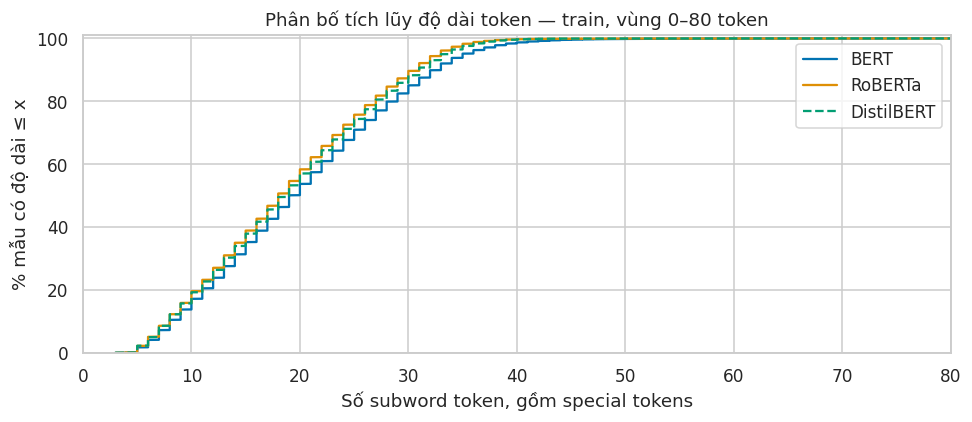

**Diễn giải:** 128 là ứng viên khởi đầu của kế hoạch. Bảng trên cho biết bao nhiêu mẫu sẽ bị cắt, chưa cho biết ảnh hưởng tới F1. Biểu đồ phóng vùng 0–80 token; các mẫu dài hơn vẫn có trong bảng và phép đếm. Chuỗi Unicode/emoji hoặc ký tự lặp có thể dài sau subword tokenization dù ít khoảng trắng. Cấu hình báo cáo đã khóa max_length=128; phép mô tả này không chọn lại cấu hình theo test.

In [12]:
from tokenizers import Tokenizer
tokenizer_revisions = {}
for architecture in ['bert','roberta','distilbert']:
    receipt = ROOT/f'experiments/best_epochs_20261103/main_results/training_receipts/{architecture}/seed_42/run_metadata.json'
    metadata = json.loads(receipt.read_text(encoding='utf-8'))
    tokenizer_revisions[metadata['checkpoint']] = metadata['checkpoint_revision']
token_rows, tokenizer_manifest, token_lengths = [], [], {}
for model_id, revision in tokenizer_revisions.items():
    model_short = {'google-bert/bert-base-cased':'BERT', 'FacebookAI/roberta-base':'RoBERTa',
                   'distilbert/distilbert-base-uncased':'DistilBERT'}[model_id]
    url = f'https://huggingface.co/{model_id}/resolve/{revision}/tokenizer.json'
    path = download(url, ROOT/'data/tokenizers'/model_short/revision/'tokenizer.json')
    tok = Tokenizer.from_file(str(path))
    tok.no_truncation(); tok.no_padding()
    tokenizer_manifest.append({'name': model_short, 'model_id': model_id, 'revision': revision,
        'url': url, 'sha256': sha256(path), 'special_tokens_included': True})
    for split in ['train','validation']:
        texts = frames[split].text.tolist()
        counts = []
        for start in range(0, len(texts), 512):
            counts.extend(len(enc.ids) for enc in tok.encode_batch(texts[start:start+512], add_special_tokens=True))
        values = np.asarray(counts)
        token_lengths[(model_short, split)] = values
        row = {'tokenizer': model_short, 'split': split, 'n_samples': len(values),
               'mean': values.mean(), 'p50': np.quantile(values,.5), 'p95': np.quantile(values,.95),
               'p99': np.quantile(values,.99), 'max': int(values.max())}
        for limit in [64,128,256]:
            row[f'over_{limit}_count'] = int((values > limit).sum())
            row[f'over_{limit}_pct'] = (values > limit).mean()*100
            row[f'tokens_removed_at_{limit}'] = int(np.maximum(values-limit, 0).sum())
        token_rows.append(row)
token_summary = pd.DataFrame(token_rows)
save_table(token_summary, 'tokenizer_lengths_train_validation')
(ROOT/'data/tokenizer_manifest.json').write_text(json.dumps(tokenizer_manifest, indent=2), encoding='utf-8')
display(token_summary[['tokenizer','split','n_samples','mean','p50','p95','p99','max']].round(3))
truncation = pd.DataFrame([
    {'tokenizer': row['tokenizer'], 'split': row['split'], 'max_length': limit,
     'samples_truncated': row[f'over_{limit}_count'], 'percent_truncated': row[f'over_{limit}_pct'],
     'tokens_removed': row[f'tokens_removed_at_{limit}']}
    for row in token_rows for limit in [64,128,256]])
save_table(truncation, 'tokenizer_truncation')
display(truncation.round(5))
outlier_rows = []
for name in ['BERT','RoBERTa','DistilBERT']:
    values = token_lengths[(name,'train')]
    for i in np.argsort(values, kind='stable')[-3:][::-1]:
        row = frames['train'].iloc[i]
        outlier_rows.append({'tokenizer': name, 'id': row.id, 'n_tokens': int(values[i]),
            'n_chars': len(row.text), 'n_words_whitespace': len(row.text.split()),
            'text_preview': row.text[:100] + ('…' if len(row.text)>100 else '')})
token_outliers = pd.DataFrame(outlier_rows)
save_table(token_outliers, 'tokenizer_outliers_train')
display(token_outliers)
fig, ax = plt.subplots(figsize=(9, 4))
for name in ['BERT','RoBERTa','DistilBERT']:
    values = token_lengths[(name,'train')]
    xs = np.sort(values)
    ax.plot(xs, np.arange(1,len(xs)+1)/len(xs)*100, label=name,
            linestyle='--' if name == 'DistilBERT' else '-')
ax.set(xlabel='Số subword token, gồm special tokens', ylabel='% mẫu có độ dài ≤ x',
       title='Phân bố tích lũy độ dài token — train, vùng 0–80 token', ylim=(0,101), xlim=(0,80))
ax.legend(); finish_figure('07_token_length_ecdf_train')
display(Markdown('**Diễn giải:** 128 là ứng viên khởi đầu của kế hoạch. Bảng trên cho biết '
    'bao nhiêu mẫu sẽ bị cắt, chưa cho biết ảnh hưởng tới F1. '
    'Biểu đồ phóng vùng 0–80 token; các mẫu dài hơn vẫn có trong bảng và phép đếm. '
    'Chuỗi Unicode/emoji hoặc ký tự lặp có thể dài sau subword tokenization dù ít khoảng trắng. '
    'Cấu hình báo cáo đã khóa max_length=128; phép mô tả này không chọn lại cấu hình theo test.'))

## Bước 13 — Ba mươi ví dụ từ train để nhóm xem thủ công

Chọn có chủ đích 28 ví dụ (mỗi nhãn một ví dụ) và thêm một mẫu ≥3 nhãn,
một mẫu neutral kèm cảm xúc. Ưu tiên 3–20 đơn vị khoảng trắng và đơn nhãn nếu có;
sắp theo ID rồi lấy mẫu với seed 42. Các ID không lặp, nguyên văn không bị sửa.
Đây là **bộ minh họa phủ nhãn**, không phải mẫu ngẫu nhiên đại diện để ước lượng tỷ lệ.

`selection_reason` giải thích cách chọn, không phải giải thích đúng/sai của nhãn.
Cột `group_review_note` để nhóm bổ sung nhận xét riêng. Nếu có file
`references/example_notes.json`, notebook ghép thêm ghi chú đọc nội dung của người chuẩn bị;
những ghi chú này là diễn giải, không thay ground truth hoặc chứng nhận nhãn đúng.

In [13]:
train = frames['train']
used, example_rows = set(), []
def choose_example(mask, reason, prefer_single=False):
    candidates = train.loc[mask & ~train.id.isin(used)].copy()
    words = candidates.text.str.split().str.len()
    short = candidates.loc[words.between(3,20)]
    if len(short):
        candidates = short
    if prefer_single:
        single = candidates.loc[candidates.labels.map(len).eq(1)]
        if len(single):
            candidates = single
    row = candidates.sort_values('id').sample(n=1, random_state=SEED).iloc[0]
    used.add(row.id)
    example_rows.append({'split':'train', 'id':row.id, 'text':row.text,
        'label_ids': ','.join(map(str,row.labels)),
        'labels': ', '.join(label_names[j] for j in row.labels),
        'n_labels': len(row.labels), 'selection_reason': reason, 'group_review_note':''})
for j, name in enumerate(label_names):
    choose_example(train.labels.map(lambda labels: j in labels), f'Minh họa nhãn {name}', prefer_single=True)
choose_example(train.labels.map(len).ge(3), 'Minh họa một bình luận có ít nhất 3 nhãn')
choose_example(train.labels.map(lambda labels: neutral_id in labels and len(labels)>1), 'Neutral cùng cảm xúc khác')
examples = pd.DataFrame(example_rows)
notes_path = ROOT/'references/example_notes.json'
notes = json.loads(notes_path.read_text(encoding='utf-8')) if notes_path.exists() else {}
examples['reading_note'] = examples.id.map(notes).fillna('')
assert len(examples) == examples.id.nunique() == 30
assert set(range(28)) == {int(j) for value in examples.label_ids for j in value.split(',')}
save_table(examples, 'examples_30')
with pd.option_context('display.max_colwidth', None, 'display.max_rows', 40):
    display(examples[['id','text','labels','reading_note']])
display(Markdown('**Cách thảo luận:** câu có từ chỉ cảm xúc rõ hay cần ngữ cảnh? '
    'Có phủ định, hàm ý, nhãn gần nghĩa, hoặc neutral đồng xuất hiện không? '
    'Nhóm ghi nhận xét vào một bản sao của CSV để lần chạy lại không ghi đè phần ghi chú.'))

,id,text,labels,reading_note
0,efajo6t,Lol alright dude. Nice chat.,admiration,Cụm Nice chat có thể là lời khen hoặc lời kết mỉa mai tùy ngữ cảnh. Dữ liệu gán admiration; chỉ câu riêng lẻ chưa đủ xác nhận sắc thái.
1,eey5g23,Why would [NAME] even care lol Reminds me of that [NAME] [NAME] I see a lot,amusement,"Dấu hiệu lol gợi sắc thái thích thú. [NAME] là phần được che trong nguồn, không nên xóa hoặc đoán tên thật."
2,edko6gj,Screaming at this reply,anger,Screaming là phản ứng mạnh nhưng cũng có thể chỉ cười hoặc bất ngờ trên mạng. Nhãn anger cần ngữ cảnh của reply để hiểu chắc hơn.
3,eeof8t8,"I just want to shake her by her shoulders and be like ""*Why are you like this?!*""",annoyance,"Câu hỏi Why are you like this?! cùng ý muốn lay vai diễn tả bực bội, phù hợp cách đọc annoyance."
4,effjfum,Trolls are okay in this sub but let's be more serious here,approval,"Vế Trolls are okay thể hiện chấp nhận, trong khi vế sau yêu cầu nghiêm túc hơn. Cần đọc cả hai vế khi xem nhãn approval."
5,eegojhf,[NAME] it’s ok the trumpet player can’t hurt you anymore,caring,"Cấu trúc it’s ok và can’t hurt you anymore là lời trấn an, gợi caring; vẫn có khả năng đùa tùy hội thoại."
6,efckxje,New to the area. I would think it's due to the cold. I havent seen my neighborhood this dark.,confusion,"Người viết chưa quen khu vực và đang phỏng đoán nguyên nhân, tạo cảm giác chưa rõ tình hình; nhãn confusion không cần từ confused xuất hiện."
7,eelvbdz,Really? I was in New York last week and had to stand in the freezing cold to pump gas twice.,curiosity,"Really? mở đầu bằng phản ứng hỏi lại, nhưng câu cũng nêu trải nghiệm trái với thông tin trước. Curiosity cần phân biệt với surprise hoặc disapproval."
8,edjsvk7,I wish I could make a garden,desire,"I wish I could là dấu hiệu trực tiếp của mong muốn, giúp minh họa desire khá rõ."
9,efdel1c,"While out at the beach for a weekend for her birthday. There was no final straw, I just wanted to.",disappointment,"Câu bị tách khỏi câu chuyện trước đó, không có dấu hiệu disappointment rõ trong đoạn riêng. Giữ nhãn gốc và ghi nhận thiếu ngữ cảnh."


**Cách thảo luận:** câu có từ chỉ cảm xúc rõ hay cần ngữ cảnh? Có phủ định, hàm ý, nhãn gần nghĩa, hoặc neutral đồng xuất hiện không? Nhóm ghi nhận xét vào một bản sao của CSV để lần chạy lại không ghi đè phần ghi chú.

## Bước 14 — Đối chiếu số đo với snapshot cố định

Các hằng số dưới đây là số đo EDA trước đó của snapshot cố định, dùng làm **mốc kiểm chứng**,
không dùng thay phép đếm. Nếu dữ liệu, mapping hoặc thuật toán sai, ô này dừng.
Đối chiếu toàn bộ 28 support của từng split, số mẫu theo số nhãn, neutral và trùng text.

In [14]:
expected_counts = {
 'train':[4130,2328,1567,2470,2939,1087,1368,2191,641,1269,2022,793,303,853,596,2662,77,1452,2086,164,1581,111,1110,153,545,1326,1060,14219],
 'validation':[488,303,195,303,397,153,152,248,77,163,292,97,35,96,90,358,13,172,252,21,209,15,127,18,68,143,129,1766],
 'test':[504,264,198,320,351,135,153,284,83,151,267,123,37,103,78,352,6,161,238,23,186,16,145,11,56,156,141,1787]}
for split in SPLITS:
    np.testing.assert_array_equal(Y[split].sum(axis=0), expected_counts[split])
np.testing.assert_array_equal(multi_stats.one_label, [36308,4548,4590])
np.testing.assert_array_equal(multi_stats.two_labels, [6541,809,774])
np.testing.assert_array_equal(multi_stats.three_or_more, [561,69,63])
np.testing.assert_array_equal(neutral_stats.neutral_with_other, [1396,174,181])
np.testing.assert_array_equal(quality.unique_texts, [43227,5423,5421])
np.testing.assert_array_equal(overlap.shared_exact_texts, [41,32,10])
np.testing.assert_array_equal(overlap.right_rows_exact, [43,37,13])
assert rare_names == ['grief','pride','relief','nervousness','embarrassment']
assert len(clean_test_ids) == 5390
verification = {'status':'passed', 'dataset_revision': REVISION,
                'checks':['sha256_3_files','schema_and_label_mapping','split_sizes','supports_28x3',
                          'label_cardinality','neutral_cooccurrence','duplicate_text','multi_hot','30_examples']}
(ROOT/'reports/verification.json').write_text(json.dumps(verification, indent=2), encoding='utf-8')
print('PASS: số liệu tính trực tiếp khớp các mốc EDA của snapshot cố định.')

PASS: số liệu tính trực tiếp khớp các mốc EDA của snapshot cố định.


## Bước 15 — Xuất kết quả để bàn giao

Xuất `Y_train/Y_validation/Y_test` và ID theo đúng thứ tự trong file `.npz`.
File này dành cho bước mô hình sau; `.npz` không chứa văn bản, phải đối chiếu ID với raw.
Xuất bảng CSV UTF-8 BOM để Excel đọc tiếng Việt, ảnh PNG và JSON kết quả.
Tất cả số liệu được xuất từ biến đã tính, tránh gõ lại nhầm.

In [15]:
for split in SPLITS:
    np.savez_compressed(ROOT/'data/processed'/f'{split}_multihot.npz',
                        Y=Y[split], ids=frames[split].id.to_numpy(dtype=str),
                        label_names=np.asarray(label_names, dtype=str))
    saved = np.load(ROOT/'data/processed'/f'{split}_multihot.npz', allow_pickle=False)
    assert np.array_equal(saved['Y'], Y[split])
    assert saved['ids'].tolist() == frames[split].id.tolist()
    assert saved['label_names'].tolist() == label_names

total_samples = sum(map(len, frames.values()))
total_multi = int(multi_stats.multi_label_samples.sum())
total_assignments = int(multi_stats.label_assignments.sum())
summary = {'samples': total_samples, 'n_labels': len(label_names),
           'label_assignments': total_assignments, 'multi_label_samples': total_multi,
           'multi_label_pct': total_multi/total_samples*100,
           'cardinality': total_assignments/total_samples,
           'density': total_assignments/(total_samples*28),
           'train_imbalance_ratio': float(imbalance_ratio),
           'rare_labels': rare_names, 'neutral_with_other': int(neutral_stats.neutral_with_other.sum()),
           'test_without_exact_train_overlap': len(clean_test_ids)}
(ROOT/'reports/summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

display(pd.Series(summary, name='value').to_frame())
print('Số bảng CSV:', len(list(TABLES.glob('*.csv'))))
print('Số hình PNG:', len(list(FIGURES.glob('*.png'))))

,value
samples,54263
n_labels,28
label_assignments,63812
multi_label_samples,8817
multi_label_pct,16.248641
cardinality,1.175976
density,0.041999
train_imbalance_ratio,184.662338
rare_labels,"[grief, pride, relief, nervousness, embarrassment]"
neutral_with_other,1751


Số bảng CSV: 18
Số hình PNG: 7


## Bước 16 — Tự kiểm tra và bàn giao cho phần mô hình

Sau notebook, nhóm cần giải thích được:

1. Vì sao tổng support lớn hơn số bình luận? Phân biệt prevalence với share of assignments.
2. Một hàng multi-hot có thể có bao nhiêu số 1? Vì sao không dùng `argmax` để lấy một nhãn duy nhất?
3. Vì sao neutral không được ép loại trừ những nhãn còn lại?
4. Vì sao xác định năm nhãn hiếm bằng train, chọn ngưỡng bằng validation?
5. Vì sao 32 chuỗi text trùng lại ảnh hưởng 37 dòng test?
6. Vì sao “30 từ” không có nghĩa “30 token BERT”?

**Bàn giao:** `data/manifest.json`, `data/labels.json`, ma trận N × 28 trong
`data/processed/`, 30 ví dụ và toàn bộ thống kê trong `reports/tables/`, bảy biểu đồ
trong `reports/figures/`, kết quả `reports/summary.json`.
Mở `reports/notebooks/01_eda.executed.ipynb` để đọc bản notebook đã chạy.

**Bước tiếp theo của đồ án:** baseline TF-IDF + One-vs-Rest Logistic Regression;
fit vectorizer chỉ trên train. Zero-shot và fine-tune BERT/RoBERTa/DistilBERT
thuộc giai đoạn sau. EDA không thay thế các thực nghiệm A/B/C/D trong kế hoạch.

## Tài liệu tham khảo

- Cấu hình snapshot/checksum: `src/datasets/goemotions.py`; lộ trình: `README.md#notebooks`.
- [Demszky et al., ACL 2020](https://aclanthology.org/2020.acl-main.372/).
- [Google Research GoEmotions README](https://github.com/google-research/google-research/blob/master/goemotions/README.md).
- [Dataset card](https://huggingface.co/datasets/google-research-datasets/go_emotions).
- [Snapshot simplified được dùng](https://huggingface.co/datasets/google-research-datasets/go_emotions/tree/add492243ff905527e67aeb8b80c082af02207c3/simplified).
- [Hugging Face Tokenizers](https://huggingface.co/docs/tokenizers/api/tokenizer).

# Phần 2. Đầu vào và tokenizer — Chương 2/3

# 06 · Kiểm đầu vào và tokenizer thực tế
Đối chiếu Word 2.3.2, 3.3 và PPT slide 6/14. Chỉ tải tokenizer nhỏ; không tải hoặc huấn luyện mô hình.

In [16]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/notebook_support.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
EXPERIMENT = ROOT/'experiments/best_epochs_20261103'
MAIN = EXPERIMENT/'main_results'
ERRORS = ROOT/'experiments/threshold_error_20261110'
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
print('báo cáo IEEE v8 · chỉ đánh giá từ dữ liệu/điểm đã lưu, không huấn luyện lại.')
from src.notebook_support import artifacts_root
from src.datasets.goemotions import load_goemotions,download,sha256,multi_hot
from tokenizers import Tokenizer
frames, labels, _ = load_goemotions(artifacts_root(),write_metadata=False)
tokenizers={};tokenizer_rows=[]
for architecture in ['bert','roberta','distilbert']:
    meta=json.loads((MAIN/f'training_receipts/{architecture}/seed_42/run_metadata.json').read_text(encoding='utf-8'))
    model_id,revision=meta['checkpoint'],meta['checkpoint_revision']
    path=download(f'https://huggingface.co/{model_id}/resolve/{revision}/tokenizer.json',ROOT/f'data/tokenizers/{architecture}/{revision}/tokenizer.json')
    tokenizer=Tokenizer.from_file(str(path));tokenizer.no_truncation();tokenizer.no_padding()
    tokenizers[architecture]=tokenizer
    tokenizer_rows.append({'mô hình':architecture,'checkpoint':model_id,'revision':revision,'sha256':sha256(path)})
display(pd.DataFrame(tokenizer_rows))
pd.set_option('display.max_colwidth', None)

báo cáo IEEE v8 · chỉ đánh giá từ dữ liệu/điểm đã lưu, không huấn luyện lại.


,mô hình,checkpoint,revision,sha256
0,bert,google-bert/bert-base-cased,cd5ef92a9fb2f889e972770a36d4ed042daf221e,5b3360be30cdf39081153cf9d30bfb0503c011462fc9f77f097127c83ef0f4d9
1,roberta,FacebookAI/roberta-base,e2da8e2f811d1448a5b465c236feacd80ffbac7b,847bbeab6174d66a88898f729d52fa8d355fafe1bea101cf960dd404581df70e
2,distilbert,distilbert/distilbert-base-uncased,12040accade4e8a0f71eabdb258fecc2e7e948be,ce64fce797c24f68df90b40a3f74f579b336a493db14bd583fd520ea0d8c9a98


## 1. Một câu được biến thành những token và ID nào?
ID chỉ là vị trí trong từ vựng riêng, không mang thứ tự lớn nhỏ về cảm xúc. Chữ hoa được giữ hoặc chuẩn hóa theo từng tokenizer.

In [17]:
sentence='Thank you, I am happy!'
rows=[]
for architecture,tok in tokenizers.items():
    encoded=tok.encode(sentence)
    rows.append({'mô hình':architecture,'token':encoded.tokens,'ID':encoded.ids,'mask':encoded.attention_mask,'số token':len(encoded.ids)})
display(pd.DataFrame(rows))
print('BERT cased: token happy có ID',tokenizers['bert'].token_to_id('happy'))

,mô hình,token,ID,mask,số token
0,bert,"[[CLS], Thank, you, ,, I, am, happy, !, [SEP]]","[101, 4514, 1128, 117, 146, 1821, 2816, 106, 102]","[1, 1, 1, 1, 1, 1, 1, 1, 1]",9
1,roberta,"[<s>, Thank, Ġyou, ,, ĠI, Ġam, Ġhappy, !, </s>]","[0, 13987, 47, 6, 38, 524, 1372, 328, 2]","[1, 1, 1, 1, 1, 1, 1, 1, 1]",9
2,distilbert,"[[CLS], thank, you, ,, i, am, happy, !, [SEP]]","[101, 4067, 2017, 1010, 1045, 2572, 3407, 999, 102]","[1, 1, 1, 1, 1, 1, 1, 1, 1]",9


BERT cased: token happy có ID 2816


## 2. Đo P95, phần bị cắt và [UNK] trên đúng dữ liệu
Đếm câu có ít nhất một [UNK], không phải số dòng bị mất. Max_length=128 tính cả token đặc biệt. Bảng test chỉ mô tả, không dùng chọn độ dài.

In [18]:
rows=[]
for architecture,tok in tokenizers.items():
    unk=tok.token_to_id('[UNK]')
    for split,frame in frames.items():
        encoded=tok.encode_batch(frame.text.tolist())
        lengths=np.array([len(e.ids) for e in encoded])
        count_unknown=sum(unk is not None and unk in e.ids for e in encoded)
        rows.append({'mô hình':architecture,'split':split,'số câu':len(frame),
                     'P95 token':np.quantile(lengths,.95),'câu >128 token':int((lengths>128).sum()),
                     'câu có [UNK]':count_unknown})
input_audit=pd.DataFrame(rows);display(input_audit)
assert input_audit[input_audit.split=='train']['P95 token'].tolist()==[35,33,34]
expected={'bert':[869,117,112],'distilbert':[847,115,108],'roberta':[0,0,0]}
for architecture,counts in expected.items():
    assert input_audit[input_audit['mô hình']==architecture]['câu có [UNK]'].tolist()==counts
print('PASS: P95 và số câu [UNK] khớp Word, không bỏ dòng dữ liệu.')

,mô hình,split,số câu,P95 token,câu >128 token,câu có [UNK]
0,bert,train,43410,35.000000,1,869
1,bert,validation,5426,36.000000,0,117
2,bert,test,5427,35.000000,0,112
3,roberta,train,43410,33.000000,4,0
4,roberta,validation,5426,33.000000,0,0
5,roberta,test,5427,33.000000,1,0
6,distilbert,train,43410,34.000000,1,847
7,distilbert,validation,5426,34.000000,0,115
8,distilbert,test,5427,34.000000,0,108


PASS: P95 và số câu [UNK] khớp Word, không bỏ dòng dữ liệu.


## 3. Padding, mask và ba trục B × L × 768
Hai câu được đệm tới độ dài L của batch; mask=0 ở vị trí đệm. Encoder nhận B×L ID, cho B×L×768 hidden; head phân loại cả câu cho B×28 logit.

In [19]:
tok=tokenizers['bert']
tok.enable_truncation(max_length=128)
tok.enable_padding(pad_id=tok.token_to_id('[PAD]'),pad_token='[PAD]')
batch=tok.encode_batch(['Thank you.','Thank you, I am happy!'])
ids=np.array([e.ids for e in batch]);mask=np.array([e.attention_mask for e in batch])
display(pd.DataFrame({'câu':['Thank you.','Thank you, I am happy!'], 'input_ids':ids.tolist(),'attention_mask':mask.tolist()}))
B,L=ids.shape
display(pd.Series({'input_ids':ids.shape,'attention_mask':mask.shape,'hidden (hình dạng lý thuyết)':(B,L,768),'logits (hình dạng lý thuyết)':(B,28)}))
print('Không chạy encoder trong cell này; hidden/logit ở đây là hình dạng, không phải đầu ra đo được.')

,câu,input_ids,attention_mask
0,Thank you.,"[101, 4514, 1128, 119, 102, 0, 0, 0, 0]","[1, 1, 1, 1, 1, 0, 0, 0, 0]"
1,"Thank you, I am happy!","[101, 4514, 1128, 117, 146, 1821, 2816, 106, 102]","[1, 1, 1, 1, 1, 1, 1, 1, 1]"


input_ids                            (2, 9)
attention_mask                       (2, 9)
hidden (hình dạng lý thuyết)    (2, 9, 768)
logits (hình dạng lý thuyết)        (2, 28)
dtype: object

Không chạy encoder trong cell này; hidden/logit ở đây là hình dạng, không phải đầu ra đo được.


## 4. Không xóa dữ liệu khi biểu diễn không có đặc trưng TF-IDF
Vector rỗng vẫn đi qua classifier và thường chịu tác động chủ yếu của intercept. Bảng này đối chiếu số câu 46/9/12 trong Word.

In [20]:
from src.final_submission import restore_baselines
import joblib
artifacts=restore_baselines(artifacts_root())
model=joblib.load(artifacts/'data/processed/baseline/balanced/full/model.joblib')
rows=[]
for split,frame in frames.items():
    matrix=model.named_steps['tfidf'].transform(frame.text.tolist())
    rows.append({'split':split,'hình dạng ma trận':matrix.shape,'vector rỗng':int((matrix.getnnz(axis=1)==0).sum())})
display(pd.DataFrame(rows))
assert [r['vector rỗng'] for r in rows]==[46,9,12]
print('PASS: 58.338 đặc trưng và số vector rỗng khớp báo cáo.')

Đã kiểm checkpoint: baseline_models.zip


,split,hình dạng ma trận,vector rỗng
0,train,"(43410, 58338)",46
1,validation,"(5426, 58338)",9
2,test,"(5427, 58338)",12


PASS: 58.338 đặc trưng và số vector rỗng khớp báo cáo.


# Phần 3. Tính tay — Chương 2

# 07 · Tính tay theo báo cáo IEEE v8
Các số hai chiều là **ví dụ giả định trong Chương 2**, không phải hidden thật của pretrained model. Mỗi cell thực hiện một bước. SGD một nhãn ở dưới khác AdamW và BCE trung bình 28 nhãn dùng khi train.

In [21]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/notebook_support.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
EXPERIMENT = ROOT/'experiments/best_epochs_20261103'
MAIN = EXPERIMENT/'main_results'
ERRORS = ROOT/'experiments/threshold_error_20261110'
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
print('báo cáo IEEE v8 · chỉ đánh giá từ dữ liệu/điểm đã lưu, không huấn luyện lại.')
from scipy.special import expit,softmax
from scipy.special import erf
pd.set_option('display.precision',9)
print('Tất cả phép tính dưới dùng float64 trên CPU.')
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', lambda x: f'{x:.9f}')

báo cáo IEEE v8 · chỉ đánh giá từ dữ liệu/điểm đã lưu, không huấn luyện lại.
Tất cả phép tính dưới dùng float64 trên CPU.


## 1. TF-IDF — từ văn bản đến vector
TF là số lần từ xuất hiện trong câu; DF là số câu chứa từ; IDF = ln((N+1)/(DF+1))+1. Nhân TF×IDF rồi chuẩn hóa L2. Đối chiếu Word 2.2.1 và PPT slide 9.

In [22]:
from src.learning.baseline_numpy import simple_tfidf
X,words,idf=simple_tfidf(['thank happy','thank','sad'])
assert words==['happy','sad','thank']
display(pd.DataFrame({'từ':words,'IDF':idf}))
display(pd.DataFrame(X,columns=words,index=['D1','D2','D3']))
w_demo=np.array([.2,-1.,2.]);bias_demo=-.5
z_tfidf=float(X[0]@w_demo+bias_demo)
print('D1: logit =',z_tfidf,'; sigmoid =',expit(z_tfidf))
assert round(z_tfidf,7)==.8698891 and round(float(expit(z_tfidf)),7)==.7047226
print('PASS: trọng số [0,2;−1;2], bias −0,5 và đầu ra khớp Word 2.2.1 / PPT slide 9.')

,từ,IDF
0,happy,1.693147181
1,sad,1.693147181
2,thank,1.287682072


,happy,sad,thank
D1,0.795960542,0.000000000,0.605348508
D2,0.000000000,0.000000000,1.000000000
D3,0.000000000,1.000000000,0.000000000


D1: logit = 0.8698891245262161 ; sigmoid = 0.7047226265945739
PASS: trọng số [0,2;−1;2], bias −0,5 và đầu ra khớp Word 2.2.1 / PPT slide 9.


## 2. Self-attention — tổng có trọng số của hai value
Q=K=V=I₂; S=QKᵀ/√2; A=softmax(S) theo hàng; O=AV. Softmax ở đây chạy theo vị trí token, không phải theo nhãn cảm xúc.

In [23]:
X=np.eye(2);Q=K=V=X
S=Q@K.T/np.sqrt(2);A=softmax(S,axis=1);O=A@V
for name,value in [('Q=K=V',X),('S',S),('A',A),('O',O)]:
    print(name);display(pd.DataFrame(value))
np.testing.assert_allclose(O[0],[.6697615493,.3302384507],atol=1e-9)
print('Mô hình thật: d_k=768/12=64, nên chia sqrt(64)=8.')

Q=K=V


,0,1
0,1.000000000,0.000000000
1,0.000000000,1.000000000


S


,0,1
0,0.707106781,0.000000000
1,0.000000000,0.707106781


A


,0,1
0,0.669761549,0.330238451
1,0.330238451,0.669761549


O


,0,1
0,0.669761549,0.330238451
1,0.330238451,0.669761549


Mô hình thật: d_k=768/12=64, nên chia sqrt(64)=8.


## 3. Residual → LayerNorm → FFN/GELU
Residual cộng lại đầu vào. LayerNorm chuẩn hóa trên chiều đặc trưng của từng token. FFN đổi biểu diễn của từng token; ví dụ dùng GELU theo x·Φ(x).

In [24]:
residual=X[0]+O[0]
eps=1e-12
normalized=(residual-residual.mean())/np.sqrt(residual.var()+eps)
W1=np.array([[1.,0.],[0.,1.],[-1.,0.],[0.,-1.]])
W2=np.array([[1.,0.,0.,0.],[0.,1.,0.,0.]])
hidden=W1@normalized
gelu=lambda x:.5*x*(1+erf(x/np.sqrt(2)))
display(pd.DataFrame({'bước':['Residual','LayerNorm (epsilon=1e-12)','FFN: nhân W1','GELU'],
                      'vector':[residual.tolist(),normalized.tolist(),hidden.tolist(),gelu(hidden).tolist()]}))
print('Bản tính tay làm tròn LayerNorm thành [1,-1] trước FFN:')
illustrative=W1@np.array([1.,-1.]);ffn=W2@gelu(illustrative)
display(pd.Series({'W1 đầu ra':illustrative.tolist(),'GELU':gelu(illustrative).tolist(),
                  'FFN sau W2':ffn.tolist(),'Residual thứ hai':(np.array([1.,-1.])+ffn).tolist()}))

,bước,vector
0,Residual,"[1.6697615493266569, 0.3302384506733431]"
1,LayerNorm (epsilon=1e-12),"[0.9999999999988854, -0.9999999999988854]"
2,FFN: nhân W1,"[0.9999999999988854, -0.9999999999988854, -0.9999999999988854, 0.9999999999988854]"
3,GELU,"[0.8413447460673356, -0.15865525393154997, -0.15865525393154997, 0.8413447460673356]"


Bản tính tay làm tròn LayerNorm thành [1,-1] trước FFN:


W1 đầu ra                                                                         [1.0, -1.0, -1.0, 1.0]
GELU                [0.8413447460685429, -0.15865525393145707, -0.15865525393145707, 0.8413447460685429]
FFN sau W2                                                    [0.8413447460685429, -0.15865525393145707]
Residual thứ hai                                               [1.8413447460685428, -1.1586552539314572]
dtype: object

## 4. BERT: hidden [CLS] → pooler → classifier
Chọn h=atanh([0,6;−0,2]), Wp=I, bp=0 để tanh trả đúng u=[0,6;−0,2]. Đây là cách dựng số minh họa; h đã là hidden sau encoder.

In [25]:
h=np.arctanh(np.array([.6,-.2]));u=np.tanh(h)
w=np.array([1.2,-.4]);bias=.1
z=float(w@u+bias);p=float(expit(z))
display(pd.Series({'hidden h':h.tolist(),'pooler u':u.tolist(),'logit z':z,'sigmoid p':p}))
assert abs(p-.7109495026250039)<1e-12

hidden h     [0.6931471805599453, -0.2027325540540822]
pooler u                   [0.6, -0.19999999999999998]
logit z                                    0.900000000
sigmoid p                                  0.710949503
dtype: object

## 5. Hai head còn lại — so theo đúng ví dụ của báo cáo
RoBERTa: dropout → dense → tanh → dropout → out_proj. DistilBERT: pre_classifier → ReLU → classifier. Dropout tắt khi minh họa.

In [26]:
h_roberta=np.array([1.,-1.]);dense=.5*h_roberta
u_roberta=np.tanh(dense);z_roberta=float(np.array([1.,-1.])@u_roberta)
h_distil=np.array([.6,-.2]);u_distil=np.maximum(h_distil,0)
z_distil=float(w@u_distil+bias)
heads=pd.DataFrame([{'mô hình':'BERT','logit':z,'sigmoid':p},
                    {'mô hình':'RoBERTa','logit':z_roberta,'sigmoid':float(expit(z_roberta))},
                    {'mô hình':'DistilBERT','logit':z_distil,'sigmoid':float(expit(z_distil))}])
display(heads)
print('Ba xác suất là số minh họa, không dùng xếp hạng mô hình.')

,mô hình,logit,sigmoid
0,BERT,0.900000000,0.710949503
1,RoBERTa,0.924234315,0.715904090
2,DistilBERT,0.820000000,0.694236340


Ba xác suất là số minh họa, không dùng xếp hạng mô hình.


## 6. BCE một nhãn → gradient → SGD
Với y=1: loss=−ln(p), ∂loss/∂z=p−y, ∂loss/∂w=(p−y)u. SGD: w_mới=w−η·gradient. Đây là phép tính một nhãn, **không chia thêm cho 2**. Đối chiếu Word 2.3.9 và PPT slide 17.

In [27]:
y=1.;eta=2e-5
loss=float(np.logaddexp(0,z)-y*z);grad_z=p-y;grad_w=grad_z*u
w_new=w-eta*grad_w
display(pd.Series({'BCE một nhãn':loss,'gradient logit':grad_z,'gradient w1':grad_w[0],
                   'w1 mới':w_new[0],'w1 mới làm tròn 7 chữ số':round(w_new[0],7)}))
eps_diff=1e-5
objective=lambda weight:np.logaddexp(0,weight@u+bias)-y*(weight@u+bias)
numerical=(objective(w+np.array([eps_diff,0]))-objective(w-np.array([eps_diff,0])))/(2*eps_diff)
np.testing.assert_allclose(numerical,grad_w[0],atol=1e-9)
assert round(w_new[0],7)==1.2000035
print('PASS: gradient giải tích khớp sai phân hữu hạn; SGD khớp báo cáo.')

BCE một nhãn                0.341153875
gradient logit             -0.289050497
gradient w1                -0.173430298
w1 mới                      1.200003469
w1 mới làm tròn 7 chữ số    1.200003500
dtype: float64

PASS: gradient giải tích khớp sai phân hữu hạn; SGD khớp báo cáo.


## 7. Chưng cất: KL từ hai phân phối giả định
KL(p||q)=Σp·ln(p/q). Đây là ví dụ giải thích pretrained DistilBERT, không phải loss fine-tune C3 trong đồ án.

In [28]:
temperature=2.
teacher=softmax(np.array([2.,1.,0.])/temperature)
student=softmax(np.array([1.5,1.,.5])/temperature)
kl=float(np.sum(teacher*np.log(teacher/student)))
display(pd.Series({'teacher q':teacher.tolist(),'student p':student.tolist(),'KL(q || p)':kl,'T² × KL':temperature**2*kl}))
assert round(kl,4)==.0191
print('PASS: ví dụ nhiệt độ T=2 khớp KL 0,0191 trong Word.')

teacher q        [0.506480391055654, 0.3071958857184984, 0.1863237232258476]
student p     [0.41922895160969764, 0.32649583579983665, 0.2542752125904656]
KL(q || p)                                                       0.019107581
T² × KL                                                          0.076430323
dtype: object

PASS: ví dụ nhiệt độ T=2 khớp KL 0,0191 trong Word.


## 8. Cấu hình đã chạy: đủ ba seed, không huấn luyện lại

In [29]:
lock=json.loads((MAIN/'LOCK_BEFORE_TEST.json').read_text(encoding='utf-8'))
rows=[]
for run in lock['runs']:
    meta=json.loads((MAIN/f"training_receipts/{run['architecture']}/seed_{run['seed']}/run_metadata.json").read_text(encoding='utf-8'))
    rows.append({'mô hình':run['architecture'],'seed':run['seed'],'epoch chọn':run['selected_epoch'],**{k:meta['config'][k] for k in ['learning_rate','epochs','batch_size','max_length']}})
display(pd.DataFrame(rows))
print('Checkpoint chọn theo Macro-F1 validation @0,5; không chọn lại theo test.')

,mô hình,seed,epoch chọn,learning_rate,epochs,batch_size,max_length
0,bert,42,7,0.000020000,8,16,128
1,bert,123,6,0.000020000,8,16,128
2,bert,2026,7,0.000020000,8,16,128
3,roberta,42,7,0.000020000,8,16,128
4,roberta,123,8,0.000020000,8,16,128
5,roberta,2026,5,0.000020000,8,16,128
6,distilbert,42,7,0.000020000,8,16,128
7,distilbert,123,8,0.000020000,8,16,128
8,distilbert,2026,8,0.000020000,8,16,128


Checkpoint chọn theo Macro-F1 validation @0,5; không chọn lại theo test.


# Phần 4. A: TF-IDF + Logistic Regression

# Học và kiểm chứng phần A: baseline GoEmotions

Đọc từ trên xuống. Mỗi cell nối một khái niệm NLP với dữ liệu hoặc kết quả thật.
Phần này đọc model đã fit; cuối phần suy luận lại toàn bộ test bằng protocol đã khóa. Không fit lại model hoặc chọn ngưỡng mới.

Nếu chưa có model: chạy `python -m scripts.baseline.run_baseline`, tiếp đến `--variant balanced`,
rồi `python -m scripts.baseline.analyze_baseline` từ gốc repo. Cài `requirements/notebooks.txt`
để chạy notebook bằng Jupyter hoặc VS Code. Phần triển khai chính nằm trong script,
nên nhóm có thể dùng cùng mã và metric khi tổng hợp A/B/C.

**Đối chiếu báo cáo IEEE v8:** A-standard chỉ để đối chứng; A-balanced/ngưỡng riêng là hàng A dùng trong so sánh chính. Bảng validation và test được ghi rõ, không lấy nhầm validation thành test.

In [30]:
from pathlib import Path
import sys
import json
import joblib
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.notebook_support import artifacts_root
from src.final_submission import restore_baselines
ARTIFACTS = restore_baselines(artifacts_root())
from src.datasets.goemotions import load_goemotions, multi_hot
from src.models.baseline import load_run_metadata, load_aligned_scores, load_thresholds
from src.evaluation.metrics import evaluate_multilabel
print('Python:', sys.version.split()[0])

Python: 3.13.9


## 1. Dữ liệu và 28 nhãn

Một câu có thể có nhiều cảm xúc. Không dùng argmax để ép chọn duy nhất một nhãn.
Dữ liệu simplified có 43.410 train và 5.426 validation. Revision/SHA-256 được kiểm
trong `src/datasets/goemotions.py`; `id` dùng để ghép kết quả các mô hình.

In [31]:
frames, labels, manifest = load_goemotions(ARTIFACTS, write_metadata=False, splits=('train', 'validation'))
train, val = frames['train'], frames['validation']
y_train = multi_hot(train['labels'].tolist(), len(labels))
y_val = multi_hot(val['labels'].tolist(), len(labels))
print('Y train:', y_train.shape, '| Y validation:', y_val.shape)
pd.DataFrame({'label_id': range(len(labels)), 'label': labels,
              'train_positive': y_train.sum(axis=0), 'val_positive': y_val.sum(axis=0)}).head(8)

Y train: (43410, 28) | Y validation: (5426, 28)


,label_id,label,train_positive,val_positive
0,0,admiration,4130,488
1,1,amusement,2328,303
2,2,anger,1567,195
3,3,annoyance,2470,303
4,4,approval,2939,397
5,5,caring,1087,153
6,6,confusion,1368,152
7,7,curiosity,2191,248


## 2. Multi-hot có nghĩa gì?

Hai nhãn admiration và gratitude được giữ đồng thời. Neutral là một cột riêng và
được giữ nguyên như dữ liệu nguồn. Ma trận sau chỉ là ví dụ minh họa.

In [32]:
example = multi_hot([[labels.index('admiration'), labels.index('gratitude')],
                     [labels.index('neutral')]], len(labels))
pd.DataFrame(example, columns=labels)[['admiration', 'gratitude', 'neutral']]

,admiration,gratitude,neutral
0,1,1,0
1,0,0,1


## 3. Nạp pipeline đã fit trên train

Pipeline gồm TF-IDF và 28 Logistic Regression nhị phân. Model và scores được
kiểm hash để tránh trộn kết quả từ các lần chạy. TF-IDF chỉ fit trên train.
Lệnh `transform`/`predict_proba` trên validation không thêm từ vào từ vựng.

In [33]:
folder = ARTIFACTS / 'data/processed/baseline/full'
metadata = load_run_metadata(folder, 'standard', labels)
model = joblib.load(folder / 'model.joblib')
scores = load_aligned_scores(folder / 'validation_scores.npz', val['id'].tolist(), labels)
print('So dac trung TF-IDF:', len(model.named_steps['tfidf'].vocabulary_))
print('So Logistic Regression:', len(model.named_steps['classifier'].estimators_))
print('Scores validation:', scores.shape)
print('So vong lap toi uu lon nhat:', max(metadata['optimizer_iterations']))

So dac trung TF-IDF: 58338
So Logistic Regression: 28
Scores validation: (5426, 28)
So vong lap toi uu lon nhat: 12


## 4. Tokenization mặc định và hạn chế

Baseline này dùng từ/cặp từ, lowercase và token pattern mặc định của scikit-learn.
Nó bỏ dấu câu, emoji và token một ký tự. `don't` có thể thành `don`; vì vậy chưa
thể nói baseline hiểu tốt mọi phủ định hoặc mỉa mai. Dùng cell sau để quan sát.

In [34]:
analyzer = model.named_steps['tfidf'].build_analyzer()
analyzer("I don't like this! 😢")

['don', 'like', 'this', 'don like', 'like this']

## 5. Điểm khác nhãn cuối như thế nào?

Chọn một ví dụ pride bị bỏ sót ở ngưỡng 0,5. Điểm các nhãn độc lập và không cần
cộng lại bằng 1. Bạn có thể đổi ID trong cell để xem một câu khác.

In [35]:
sample_id = 'eczwil0'
i = val.index[val['id'] == sample_id][0]
print(val.loc[i, 'text'])
print('Nhan that:', [labels[j] for j in val.loc[i, 'labels']])
view = pd.DataFrame({'label': labels, 'score': scores[i], 'predicted_at_0_5': scores[i] >= 0.5})
view.sort_values('score', ascending=False).head(6)

I am so proud of this community.
Nhan that: ['pride']


,label,score,predicted_at_0_5
21,pride,0.377635065,False
0,admiration,0.359615499,False
27,neutral,0.074780591,False
17,joy,0.058781924,False
25,sadness,0.042665539,False
7,curiosity,0.039619186,False


## 6. Micro/Macro-F1 và Hamming Loss

Macro-F1 lấy trung bình đều 28 F1, Micro-F1 cộng TP/FP/FN trước khi tính.
Hamming Loss là tỷ lệ các ô nhãn sai; cần đọc cùng Recall và F1 nhãn hiếm.
Hàm metric còn lưu TP/FP/FN/TN để tự kiểm công thức.

In [36]:
metric = evaluate_multilabel(y_val, scores, labels)
pd.Series({key: metric[key] for key in ('macro_f1', 'micro_f1', 'micro_precision',
                                     'micro_recall', 'hamming_loss', 'empty_prediction_count')})

macro_f1                    0.202456592
micro_f1                    0.375986995
micro_precision             0.725358423
micro_recall                0.253761755
hamming_loss                0.035372018
empty_prediction_count   3271.000000000
dtype: float64

## 7. So sánh ngưỡng 0,5, ngưỡng chung và ngưỡng riêng

Tất cả lựa chọn ngưỡng được thực hiện trên validation. Hàng chọn ngưỡng đo trên
chính tập dùng chọn ngưỡng, nên có thể lạc quan. Test sau freeze mới xác nhận.
Class weighting là biến thể model khác, phải có ngưỡng của chính model đó.

In [37]:
rows = []
for variant, location in [('standard', ARTIFACTS/'data/processed/baseline/full'),
                          ('balanced', ARTIFACTS/'data/processed/baseline/balanced/full')]:
    saved = json.loads((location/'analysis_validation.json').read_text(encoding='utf-8'))
    for mode, key in [('fixed', 'fixed_0_5'), ('global', 'global_on_validation'),
                      ('tuned', 'tuned_on_validation')]:
        item = saved[key]
        rows.append({'variant': variant, 'threshold_mode': mode,
                     **{key: item[key] for key in ('macro_f1', 'micro_f1', 'hamming_loss')}})
pd.DataFrame(rows)

,variant,threshold_mode,macro_f1,micro_f1,hamming_loss
0,standard,fixed,0.202456592,0.375986995,0.035372018
1,standard,global,0.409350806,0.510020159,0.054394187
2,standard,tuned,0.439074472,0.542749896,0.043296825
3,balanced,fixed,0.456249193,0.509941804,0.053209415
4,balanced,global,0.465984230,0.517609177,0.047331631
5,balanced,tuned,0.490054415,0.546680148,0.044264388


## 8. Nhãn hiếm và cặp lỗi

Năm nhãn hiếm được xác định từ train. Bảng FN(A)+FP(B) chỉ đếm hai lỗi trong
cùng câu; khác với nhãn thật đồng xuất hiện. Một câu có thể góp nhiều cặp.

In [38]:
per_label = pd.read_csv(folder/'per_label_validation.csv')
per_label.nsmallest(5, 'train_support')[['label', 'train_support', 'validation_support',
                                      'f1_fixed', 'f1_global_val', 'f1_tuned_val']]

,label,train_support,validation_support,f1_fixed,f1_global_val,f1_tuned_val
16,grief,77,13,0.000000000,0.000000000,0.000000000
21,pride,111,15,0.000000000,0.333333333,0.333333333
23,relief,153,18,0.000000000,0.000000000,0.105263158
19,nervousness,164,21,0.000000000,0.086956522,0.090909091
12,embarrassment,303,35,0.108108108,0.105263158,0.363636364


In [39]:
pairs = pd.read_csv(folder/'label_error_pairs_validation.csv')
pairs[(pairs['missed_label'] != 'neutral') & (pairs['extra_label'] != 'neutral')].head(6)

,missed_label,extra_label,count,missed_label_total_fn,fraction_of_fn,example_id
13,admiration,love,10,311,0.032154341,ee9xgzw
17,joy,love,8,147,0.054421769,ed0ht04
19,joy,admiration,7,147,0.047619048,edopy68
25,approval,love,5,384,0.013020833,ed031mb
26,gratitude,joy,5,81,0.061728395,eexk0cl
29,approval,admiration,4,384,0.010416667,edcmnk3


## 9. Tự nhập văn bản, xem score và ngưỡng

Đổi câu tiếng Anh bên dưới. Dùng model balanced và ngưỡng riêng đã chọn từ
validation. Demo cuối của nhóm vẫn phải dùng C tốt nhất theo yêu cầu cô.

In [40]:
text = 'I am so proud of you!'
balanced_folder = ARTIFACTS/'data/processed/baseline/balanced/full'
balanced_meta = load_run_metadata(balanced_folder, 'balanced', labels)
balanced_model = joblib.load(balanced_folder/'model.joblib')
thresholds = np.broadcast_to(load_thresholds(balanced_folder, balanced_meta, 'tuned'), (len(labels),))
new_scores = balanced_model.predict_proba([text])[0]
pd.DataFrame({'label': labels, 'score': new_scores, 'threshold': thresholds,
              'predicted': new_scores >= thresholds}).sort_values('score', ascending=False).head(6)

,label,score,threshold,predicted
21,pride,0.999968510,0.800000000,True
0,admiration,0.912555348,0.550000000,True
17,joy,0.283660694,0.700000000,False
15,gratitude,0.231854062,0.750000000,False
13,excitement,0.200819375,0.600000000,False
7,curiosity,0.167608599,0.700000000,False


## 10. Việc bạn cần tự giải thích

1. Vì sao số feature là 58.338 còn số nhãn là 28?
2. Vì sao không fit TF-IDF trên validation/test?
3. Vì sao weighting có thể tăng Recall và cả FP?
4. Vì sao score pride 0,3776 không vượt ngưỡng 0,5?
5. Vì sao điểm tuned-validation chưa phải cải thiện trên test?
6. Vì sao bảng cặp lỗi không phải bảng nhãn thật đồng xuất hiện?

Xem `README.md` để chạy lại và `data/processed/baseline/full/per_label_validation.csv` để dùng số thật.
Nguồn: [bài báo GoEmotions](https://aclanthology.org/2020.acl-main.372/),
[TF-IDF](https://scikit-learn.org/1.7/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html),
[One-vs-Rest](https://scikit-learn.org/1.7/modules/generated/sklearn.multiclass.OneVsRestClassifier.html),
[chọn ngưỡng](https://scikit-learn.org/1.7/modules/classification_threshold.html).

## 11. Đọc kết quả test sau khi khóa cấu hình

Cell dưới chỉ đọc kết quả đã lưu, không học lại và không chọn ngưỡng bằng test.
Bảng có sáu cấu hình đã quyết định từ validation. Đừng chọn lại model chỉ vì một hàng test cao hơn.
Nếu chưa có file, tiếp tục pipeline nhóm theo `README.md`; không điền số dự kiến.

In [41]:
from src.datasets.goemotions import sha256, REVISION
test_path = ARTIFACTS / 'data/processed/baseline/final/final_results.json'
if not test_path.exists():
    raise FileNotFoundError('Thiếu kết quả A đã khóa; không suy ra từ validation.')
else:
    final = json.loads(test_path.read_text(encoding='utf-8'))
    protocol_path = ARTIFACTS / 'data/processed/baseline/final_protocol.json'
    if final['protocol_sha256'] != sha256(protocol_path) or final['data_revision'] != REVISION:
        raise ValueError('Kết quả test không khớp protocol hoặc revision dữ liệu')
    print('Cấu hình chọn trên validation:', final['selected_on_validation'])
    test_rows = [dict(configuration=r['name'], **{k: r['metrics'][k] for k in
                 ['macro_f1', 'micro_f1', 'macro_precision', 'macro_recall',
                  'micro_precision', 'micro_recall', 'hamming_loss']}) for r in final['results']]
    display(pd.DataFrame(test_rows))

Cấu hình chọn trên validation: balanced_tuned


,configuration,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss
0,standard_fixed,0.196338893,0.379957756,0.612793518,0.139577772,0.738258094,0.255806605,0.034773224
1,standard_global,0.409569218,0.504744504,0.463091809,0.447578481,0.402519271,0.676568178,0.055298902
2,standard_tuned,0.413425640,0.532991761,0.438380936,0.436139646,0.474365295,0.608152947,0.044387849
3,balanced_fixed,0.444052109,0.502363995,0.377676632,0.569585637,0.404335260,0.663137936,0.054719787
4,balanced_global,0.453027045,0.515670651,0.402945787,0.536328311,0.444737144,0.613525043,0.048000737
5,balanced_tuned,0.449263554,0.527738928,0.437235739,0.488342083,0.456136311,0.626007268,0.046664824


## 12. Cấu hình và bằng chứng huấn luyện đã chạy trước đây
    Các tham số, số mẫu, thời gian fit và số vòng tối ưu dưới đây lấy từ metadata thật.
    Lần chạy notebook này **không gọi fit lại** hai model full. Code fit nằm ở
    `scripts/baseline/run_baseline.py`; ví dụ học trực tiếp nằm trong Phần 8 của notebook này.

In [42]:
training_receipts = []
for variant in ('standard', 'balanced'):
    base = ARTIFACTS/'data/processed/baseline'
    run = base/('full' if variant == 'standard' else 'balanced/full')
    meta = load_run_metadata(run, variant, labels)
    assert meta['n_train'] == 43410 and not meta['smoke']
    training_receipts.append(dict(variant=variant, n_train=meta['n_train'],
        fit_seconds=meta['fit_seconds'], **meta['config']))
display(pd.DataFrame(training_receipts))
print('Nguồn: metadata huấn luyện cũ, không phải thời gian train mới của notebook.')

,variant,n_train,fit_seconds,ngram_range,min_df,max_features,C,solver,max_iter,class_weight,random_state
0,standard,43410,12.870000000,"[1, 2]",2,100000,1.000000000,liblinear,1000,None,42
1,balanced,43410,22.630000000,"[1, 2]",2,100000,1.000000000,liblinear,1000,balanced,42


Nguồn: metadata huấn luyện cũ, không phải thời gian train mới của notebook.


## 13. Chạy suy luận test thật lại cho cả hai model
    Cell này thực sự gọi `predict_proba` trên **5.427 mẫu test**, áp ba ngưỡng đã khóa,
    tính lại đủ bảy metric và so scores/metric với bộ số báo cáo. Output mới lưu riêng
    trong `reports/notebook_replay/`. Test không dùng để chọn cấu hình.

In [43]:
from src.notebook_support import replay_test
fresh_test = pd.concat([replay_test(ARTIFACTS, 'A_'+variant)
                       for variant in ('standard', 'balanced')], ignore_index=True)
assert len(fresh_test) == 6 and (fresh_test.n_samples == 5427).all()
display(fresh_test)
print('PASS: đã suy luận thật hai model A, sáu cấu hình test khớp báo cáo.')

PASS A: 12 dòng từ scores thật


,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss,metric_max_abs_diff,score_max_abs_diff,score_tolerance,changed_label_decisions,exact_metric_match
0,A_standard,42,test,fixed,5427,0.196338893,0.379957756,0.612793518,0.139577772,0.738258094,0.255806605,0.034773224,0.000000000,0.000000000,0.000000000,0,True
1,A_standard,42,test,global,5427,0.409569218,0.504744504,0.463091809,0.447578481,0.402519271,0.676568178,0.055298902,0.000000000,0.000000000,0.000000000,0,True
2,A_standard,42,test,tuned,5427,0.413425640,0.532991761,0.438380936,0.436139646,0.474365295,0.608152947,0.044387849,0.000000000,0.000000000,0.000000000,0,True
3,A_balanced,42,test,fixed,5427,0.444052109,0.502363995,0.377676632,0.569585637,0.404335260,0.663137936,0.054719787,0.000000000,0.000000000,0.000000000,0,True
4,A_balanced,42,test,global,5427,0.453027045,0.515670651,0.402945787,0.536328311,0.444737144,0.613525043,0.048000737,0.000000000,0.000000000,0.000000000,0,True
5,A_balanced,42,test,tuned,5427,0.449263554,0.527738928,0.437235739,0.488342083,0.456136311,0.626007268,0.046664824,0.000000000,0.000000000,0.000000000,0,True


PASS: đã suy luận thật hai model A, sáu cấu hình test khớp báo cáo.


## 14. Đối chiếu cột A của Bảng 5.9 — năm nhãn hiếm
Cột A của Word so **standard/0,5 → balanced/ngưỡng riêng**, thay cả weighting lẫn ngưỡng. Thêm balanced/0,5 để thấy đối chứng chỉ thay ngưỡng. Các số dưới được tính từ scores test đã lưu, không chọn lại theo test.

In [44]:
from src.evaluation.protocols import read_json
from src.notebook_support import benchmark
_, all_frames, label_names=benchmark(str(ARTIFACTS),('A',))
test_frame=all_frames['test'];test_truth=multi_hot(test_frame.labels.tolist())
protocol=read_json(ARTIFACTS/'data/processed/baseline/final_protocol.json')
rare=['grief','pride','relief','nervousness','embarrassment'];tables={}
for variant,mode in [('standard','fixed'),('balanced','fixed'),('balanced','tuned')]:
    points=load_aligned_scores(ARTIFACTS/f'data/processed/baseline/final/{variant}_test_scores.npz',test_frame.id.tolist(),label_names)
    thresholds=next(c['thresholds'] for c in protocol['configurations'] if c['variant']==variant and c['threshold_mode']==mode)
    metric=evaluate_multilabel(test_truth,points,label_names,thresholds)
    tables[f'{variant}/{mode}']=pd.DataFrame(metric['per_label']).set_index('label').loc[rare,'f1']
rare_a=pd.DataFrame(tables)
display(rare_a)
display(rare_a.mean().rename('Trung bình F1 năm nhãn'))
expected=json.loads((ROOT/'experiments/best_epochs_20261103/main_results/report_data/a_rare.json').read_text(encoding='utf-8'))
np.testing.assert_allclose(rare_a['standard/fixed'],expected['before'],atol=1e-12)
np.testing.assert_allclose(rare_a['balanced/tuned'],expected['after'],atol=1e-12)
print('PASS: cột A trước/sau của Bảng 5.7 khớp, không trộn tác động weighting với ngưỡng.')

,standard/fixed,balanced/fixed,balanced/tuned
label,,,
grief,0.000000000,0.428571429,0.461538462
pride,0.000000000,0.461538462,0.416666667
relief,0.000000000,0.133333333,0.117647059
nervousness,0.000000000,0.297872340,0.171428571
embarrassment,0.000000000,0.333333333,0.277777778


standard/fixed   0.000000000
balanced/fixed   0.330929779
balanced/tuned   0.289011707
Name: Trung bình F1 năm nhãn, dtype: float64

PASS: cột A trước/sau của Bảng 5.7 khớp, không trộn tác động weighting với ngưỡng.


# Phần 5. B: BART-MNLI

# B — BART-MNLI zero-shot: kiểm số từ scores đã lưu
    **Phạm vi:** lần chạy này tính lại metric trên toàn bộ validation/test từ scores
    NLI lịch sử; không nạp lại BART hoặc chạy mới 28 cặp NLI cho mỗi câu.
    B không fine-tune trọng số bằng GoEmotions. Ngưỡng đã khóa từ validation.
    Mỗi bảng dưới được tính/kiểm khi chạy cell, không chép số dự kiến vào notebook.

**Đối chiếu:** báo cáo IEEE v8 Bảng 5.1/5.6, PPT slide 10/22/23. Ngưỡng dùng nhãn validation; trọng số BART không fine-tune.

In [45]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/notebook_support.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.notebook_support import artifacts_root
from src.datasets.goemotions import load_goemotions, multi_hot, sha256, REVISION
from src.evaluation.protocols import read_json
from src.evaluation.metrics import evaluate_multilabel
from src.models.transformer import METRIC_NAMES
ARTIFACTS = artifacts_root()
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_colwidth', 100)
print('Python:', sys.version.split()[0])
print('Dataset revision:', REVISION)
print('Artifacts:', ARTIFACTS.name)

Python: 3.13.9
Dataset revision: add492243ff905527e67aeb8b80c082af02207c3
Artifacts: final_submission


## 1. Checkpoint, revision, template và trạng thái run thật

In [46]:
from src.models.zero_shot import CHECKPOINT, HYPOTHESIS_TEMPLATE
B = ARTIFACTS/'data/processed/zero_shot/full'
metadata = read_json(B/'run_metadata.json')
protocol = read_json(B/'final_protocol.json')
assert metadata['checkpoint'] == CHECKPOINT and metadata['multi_label']
assert metadata['status'] == 'complete' and not metadata['smoke']
display(pd.Series({k: metadata[k] for k in ('checkpoint', 'model_revision',
    'hypothesis_template', 'dtype', 'device', 'sample_count', 'created_at_utc')}))
print('Fine-tune trọng số: KHÔNG. Tìm ngưỡng: đã thực hiện trên validation trước test.')

checkpoint                             facebook/bart-large-mnli
model_revision         d7645e127eaf1aefc7862fd59a17a5aa8558b8ce
hypothesis_template                     This text expresses {}.
dtype                                                   float16
device                                                     cuda
sample_count                                               5426
created_at_utc                 2026-10-08T15:14:08.822646+00:00
dtype: object

Fine-tune trọng số: KHÔNG. Tìm ngưỡng: đã thực hiện trên validation trước test.


## 2. Kiểm điểm B đã lưu
Chỉ kiểm phạm vi B: ID, hash, mapping và sáu hàng validation/test ở ba chế độ. Không chạy các mô hình C.

In [47]:
from src.notebook_support import benchmark
from src.models.baseline import load_aligned_scores
verified, frames, labels = benchmark(str(ARTIFACTS), ("B",))
b_rows = pd.DataFrame([r for r in verified['records'] if r['system'] == 'B_bart_mnli'])
assert len(b_rows) == 6
display(b_rows)
print('Sai lệch metric lớn nhất với CSV báo cáo:', verified['metric_max_absolute_difference'])

PASS B: 6 dòng từ scores thật


,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss
0,B_bart_mnli,None,validation,fixed,5426,0.105982494,0.102664559,0.065236759,0.893591274,0.055256032,0.722884013,0.530659260
1,B_bart_mnli,None,validation,global,5426,0.150195171,0.146666667,0.099777160,0.763511095,0.083925741,0.581034483,0.283923964
2,B_bart_mnli,None,validation,tuned,5426,0.163271946,0.176172649,0.098974316,0.790312972,0.099767210,0.752351097,0.295482070
3,B_bart_mnli,None,test,fixed,5427,0.103490038,0.100750507,0.063464973,0.893504446,0.054194569,0.714804866,0.531456474
4,B_bart_mnli,None,test,global,5427,0.147298259,0.144921774,0.095978780,0.761396361,0.082889889,0.575920367,0.283062202
5,B_bart_mnli,None,test,tuned,5427,0.160880983,0.175184098,0.097248045,0.787247955,0.099176662,0.749881498,0.294104872


Sai lệch metric lớn nhất với CSV báo cáo: 0.0


## 3. Ghép scores theo ID và lấy một ví dụ NLI thật
    HF trả nhãn theo điểm giảm dần. Cell kiểm cách khôi phục đúng thứ tự 28 cột
    bằng một hàng scores thật. Đây là kiểm mapping, không phải suy luận BART mới.

In [48]:
from src.models.zero_shot import map_pipeline_scores
val = frames['validation']
val_scores = load_aligned_scores(B/'validation_scores.npz', val.id.tolist(), labels)
i = 0
order = np.argsort(-val_scores[i])
hf_order = {'labels': [labels[j] for j in order], 'scores': val_scores[i, order].tolist()}
np.testing.assert_array_equal(map_pipeline_scores(hf_order, labels)[0], val_scores[i])
print('ID:', val.id.iloc[i], '\nVăn bản:', val.text.iloc[i])
print('Nhãn thật:', [labels[j] for j in val.labels.iloc[i]])
display(pd.DataFrame({'label': labels, 'NLI_score': val_scores[i]}).sort_values('NLI_score', ascending=False))

ID: edgurhb 
Văn bản: Is this in New Orleans?? I really feel like this is New Orleans.
Nhãn thật: ['neutral']


,label,NLI_score
6,confusion,0.999549687
26,surprise,0.999115229
7,curiosity,0.998951554
19,nervousness,0.995032251
8,desire,0.993586838
13,excitement,0.972283423
14,fear,0.956684768
3,annoyance,0.951751232
0,admiration,0.949785948
22,realization,0.940133572


## 4. Tính metric và phân tích nhãn dự đoán quá nhiều
    Scores NLI chưa được hiệu chuẩn thành xác suất cảm xúc. Kết quả B thấp được giữ
    nguyên; không đổi template/ngưỡng theo test để làm đẹp số đã báo cáo.

In [49]:
metrics = evaluate_multilabel(multi_hot(val.labels.tolist()), val_scores, labels, 0.5)
np.testing.assert_allclose([metrics[k] for k in METRIC_NAMES],
                           [metadata['metrics'][k] for k in METRIC_NAMES], atol=1e-12, rtol=0)
display(pd.Series({k: metrics[k] for k in (*METRIC_NAMES, 'mean_predicted_labels', 'empty_prediction_count')}))
display(pd.DataFrame(metrics['per_label'])[['label', 'support', 'predicted_support', 'precision', 'recall', 'f1']])

macro_f1                  0.105982494
micro_f1                  0.102664559
macro_precision           0.065236759
macro_recall              0.893591274
micro_precision           0.055256032
micro_recall              0.722884013
hamming_loss              0.530659260
mean_predicted_labels    15.382602285
empty_prediction_count    2.000000000
dtype: float64

,label,support,predicted_support,precision,recall,f1
0,admiration,488,2795,0.158855098,0.909836066,0.270484313
1,amusement,303,3353,0.088875634,0.983498350,0.163019694
2,anger,195,3415,0.055051245,0.964102564,0.104155125
3,annoyance,303,3940,0.074873096,0.973597360,0.139052557
4,approval,397,3175,0.100787402,0.806045340,0.179171333
5,caring,153,3032,0.041886544,0.830065359,0.079748823
6,confusion,152,4599,0.032398347,0.980263158,0.062723637
7,curiosity,248,4398,0.055707140,0.987903226,0.105467068
8,desire,77,4025,0.019130435,1.000000000,0.037542662
9,disappointment,163,3387,0.046058459,0.957055215,0.087887324


## 5. So sánh ba ngưỡng đã khóa trên validation và test

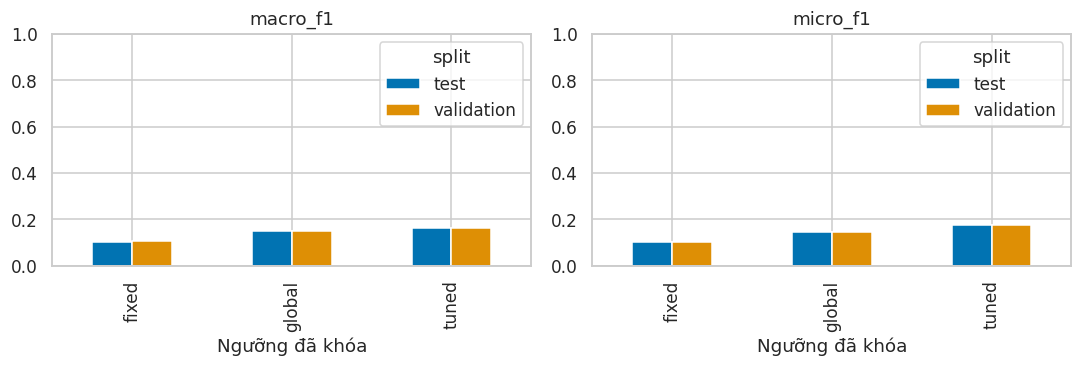

B chỉ có một run; không tạo mean±std từ một run.


In [50]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric in zip(axes, ('macro_f1', 'micro_f1')):
    b_rows.pivot(index='threshold_mode', columns='split', values=metric).plot.bar(ax=ax)
    ax.set_title(metric); ax.set_ylim(0, 1); ax.set_xlabel('Ngưỡng đã khóa')
plt.tight_layout(); plt.show(); plt.close()
print('B chỉ có một run; không tạo mean±std từ một run.')

## 6. Cách chạy lại suy luận NLI khi cần
    Code thực thi nằm tại `scripts/zero_shot/run_zero_shot.py`: nạp pretrained,
    tạo 28 giả thuyết, dự đoán `multi_label=True`, ghép nhãn và lưu từng batch.
    Một lượt full trước đây mất khoảng 19 phút cho validation trên máy chạy.
    Notebook đã chạy này dùng lại scores đó và đã đối chiếu đủ sáu dòng B.

In [51]:
print('Đã tính lại B từ scores lịch sử:', len(b_rows), 'dòng; số mẫu theo split:')
display(b_rows.groupby('split')['n_samples'].first())
print('NLI inference mới trong notebook này: KHÔNG; huấn luyện lại: KHÔNG.')

Đã tính lại B từ scores lịch sử: 6 dòng; số mẫu theo split:


split
test          5427
validation    5426
Name: n_samples, dtype: int64

NLI inference mới trong notebook này: KHÔNG; huấn luyện lại: KHÔNG.


# Phần 6. C1/C2/C3: chín lượt và chẩn đoán epoch

# 04 · C1 BERT / C2 RoBERTa / C3 DistilBERT — kết quả báo cáo
Đối chiếu báo cáo IEEE v8 Bảng 5.1–5.5, B.2–B.3 và PPT slide 18–28, 38–43. Chạy từng cell để tính lại từ đủ chín bộ điểm, chọn epoch/đại diện/ngưỡng theo hồ sơ validation đã khóa. Không huấn luyện lại.

In [52]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/notebook_support.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
EXPERIMENT = ROOT/'experiments/best_epochs_20261103'
MAIN = EXPERIMENT/'main_results'
ERRORS = ROOT/'experiments/threshold_error_20261110'
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
print('báo cáo IEEE v8 · chỉ đánh giá từ dữ liệu/điểm đã lưu, không huấn luyện lại.')
import hashlib
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss
from src import report_figures as charts
ROOT_REPO=ROOT;ROOT=EXPERIMENT
read=lambda path:json.loads(path.read_text(encoding='utf-8'))
sha=lambda path:hashlib.sha256(path.read_bytes()).hexdigest()
lock=read(MAIN/'LOCK_BEFORE_TEST.json');selection=read(MAIN/'selection.json')
assert sha(MAIN/'selection.json')==lock['selection_sha256']
display(pd.DataFrame(selection['architecture_summaries_validation']))
print('Mô hình demo:',selection['architecture'],'seed',selection['seed'])

báo cáo IEEE v8 · chỉ đánh giá từ dữ liệu/điểm đã lưu, không huấn luyện lại.


,architecture,validation_macro_f1_mean,validation_macro_f1_std,parameter_count
0,roberta,0.480139,0.012193,124667164
1,distilbert,0.470032,0.003411,66975004
2,bert,0.460801,0.004375,108331804


Mô hình demo: roberta seed 2026


## 1. Tính lại chỉ số test từ đủ chín bộ điểm
Giữ đủ 28 nhãn, dùng `score ≥ threshold`; Macro-F1 gồm cả nhãn có F1 bằng 0. Hai chế độ ngưỡng được áp trên cùng một bộ điểm của từng checkpoint.

In [53]:
frame = pd.read_parquet(MAIN / "data/raw/test-00000-of-00001.parquet")
records = []
for run in lock["runs"]:
    protocol_path = MAIN / Path(run["protocol"].replace("\\", "/"))
    assert sha(protocol_path) == run["protocol_sha256"]
    protocol = read(protocol_path)
    folder = protocol_path.parent
    receipt = read(folder / "test_results.json")
    assert receipt["scores_sha256"] == sha(folder / "test_scores.npz")
    with np.load(folder / "test_scores.npz", allow_pickle=False) as saved:
        ids, points = saved["ids"].astype(str), saved["scores"]
        labels = saved["label_names"].astype(str).tolist()
    assert labels == protocol["label_names"] and len(labels) == 28
    by_id = dict(zip(frame.id.astype(str), frame.labels))
    truth = np.zeros_like(points, dtype=np.uint8)
    for i, ident in enumerate(ids): truth[i, by_id[ident]] = 1
    assert points.shape == truth.shape == (5427, 28)
    for config in protocol["configurations"]:
        if config["threshold_mode"] not in ("fixed", "tuned"): continue
        prediction = points >= np.asarray(config["thresholds"])
        row = dict(model=run["architecture"], seed=run["seed"], epoch=run["selected_epoch"], mode=config["threshold_mode"])
        for average in ("macro", "micro"):
            row[average+"_f1"] = f1_score(truth, prediction, average=average, zero_division=0)
            row[average+"_precision"] = precision_score(truth, prediction, average=average, zero_division=0)
            row[average+"_recall"] = recall_score(truth, prediction, average=average, zero_division=0)
        row["hamming_loss"] = hamming_loss(truth, prediction)
        records.append(row)
actual = pd.DataFrame(records)
csv = pd.read_csv(MAIN / "report_data/all_runs.csv")
for row in records:
    expected = csv[(csv.system == "C_"+row["model"]) & (csv.seed == row["seed"]) & (csv.split == "test") & (csv.threshold_mode == row["mode"])].iloc[0]
    for metric in ("macro_f1", "micro_f1", "macro_precision", "macro_recall", "micro_precision", "micro_recall", "hamming_loss"):
        assert abs(row[metric]-expected[metric]) < 1e-12
print("Đã đối chiếu 18 hàng test × 7 chỉ số từ điểm dự đoán thật.")
display(actual[["model", "seed", "epoch", "mode", "macro_f1", "micro_f1", "hamming_loss"]].round(4))

Đã đối chiếu 18 hàng test × 7 chỉ số từ điểm dự đoán thật.


,model,seed,epoch,mode,macro_f1,micro_f1,hamming_loss
0,bert,42,7,fixed,0.474500,0.573800,0.033300
1,bert,42,7,tuned,0.502200,0.568100,0.041000
2,bert,123,6,fixed,0.470700,0.568000,0.033100
3,bert,123,6,tuned,0.491100,0.577600,0.038700
4,bert,2026,7,fixed,0.463700,0.570100,0.033600
5,bert,2026,7,tuned,0.488100,0.569500,0.041700
6,roberta,42,7,fixed,0.478100,0.571500,0.032900
7,roberta,42,7,tuned,0.512300,0.589100,0.037600
8,roberta,123,8,fixed,0.467900,0.575500,0.032800
9,roberta,123,8,tuned,0.501600,0.588800,0.038000


## 2. Mean ± sample std của ba seed
Tính trên số gốc chưa làm tròn; độ lệch chuẩn mẫu dùng `ddof=1`.

macro_f1          micro_f1          hamming_loss         
                     mean      std     mean      std         mean      std
model      mode                                                           
bert       fixed 0.469636 0.005473 0.570629 0.002937     0.033356 0.000251
           tuned 0.493794 0.007451 0.571725 0.005126     0.040450 0.001581
distilbert fixed 0.472875 0.003889 0.570709 0.000670     0.032876 0.000064
           tuned 0.497209 0.002687 0.577897 0.006898     0.038919 0.001188
roberta    fixed 0.476459 0.007916 0.574146 0.002311     0.032523 0.000582
           tuned 0.510117 0.007619 0.590873 0.003315     0.037713 0.000226

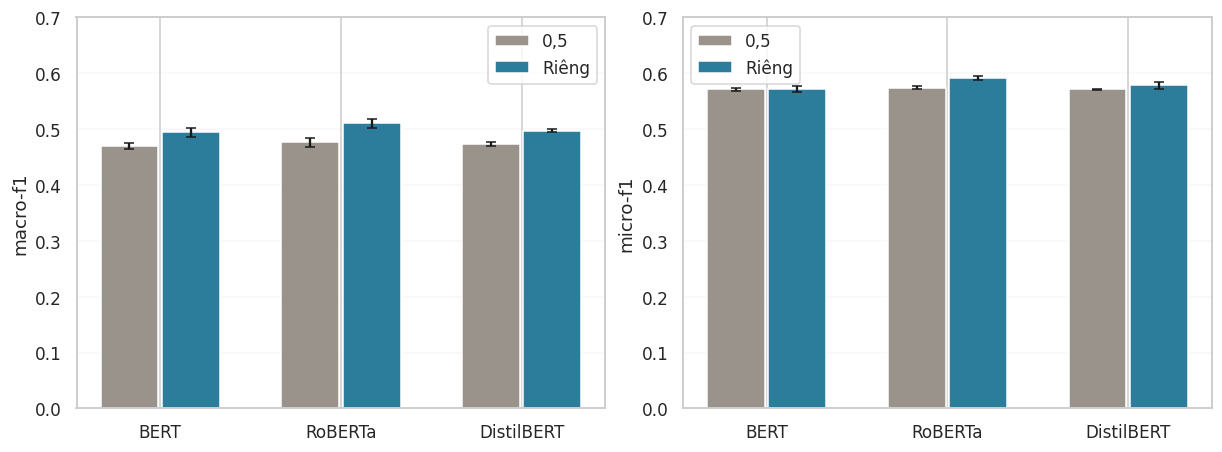

Mean ± std mẫu từ đúng ba seed; biểu đồ tương ứng Hình 5.1 và PPT slide 24.


In [54]:
summary=actual.groupby(['model','mode'])[['macro_f1','micro_f1','hamming_loss']].agg(['mean','std'])
display(summary.round(6))
fig=charts.model_f1(actual);plt.show();plt.close(fig)
print('Mean ± std mẫu từ đúng ba seed; biểu đồ tương ứng Hình 5.1 và PPT slide 24.')

## 3. Đường học và epoch chọn
Đường đứt đánh dấu checkpoint tốt nhất theo validation trong từng seed. Đường chấm là mốc validation của lượt chạy ban đầu; không phải kết quả test.

,model,seed,epoch,val_macro_f1,val_bce
6,BERT,42,7,0.455969,0.106145
13,BERT,123,6,0.461938,0.101499
22,BERT,2026,7,0.464495,0.105355
30,RoBERTa,42,7,0.484181,0.094248
39,RoBERTa,123,8,0.466438,0.097775
44,RoBERTa,2026,5,0.489797,0.088151
54,DistilBERT,42,7,0.468009,0.105085
63,DistilBERT,123,8,0.468118,0.106701
71,DistilBERT,2026,8,0.473971,0.105625


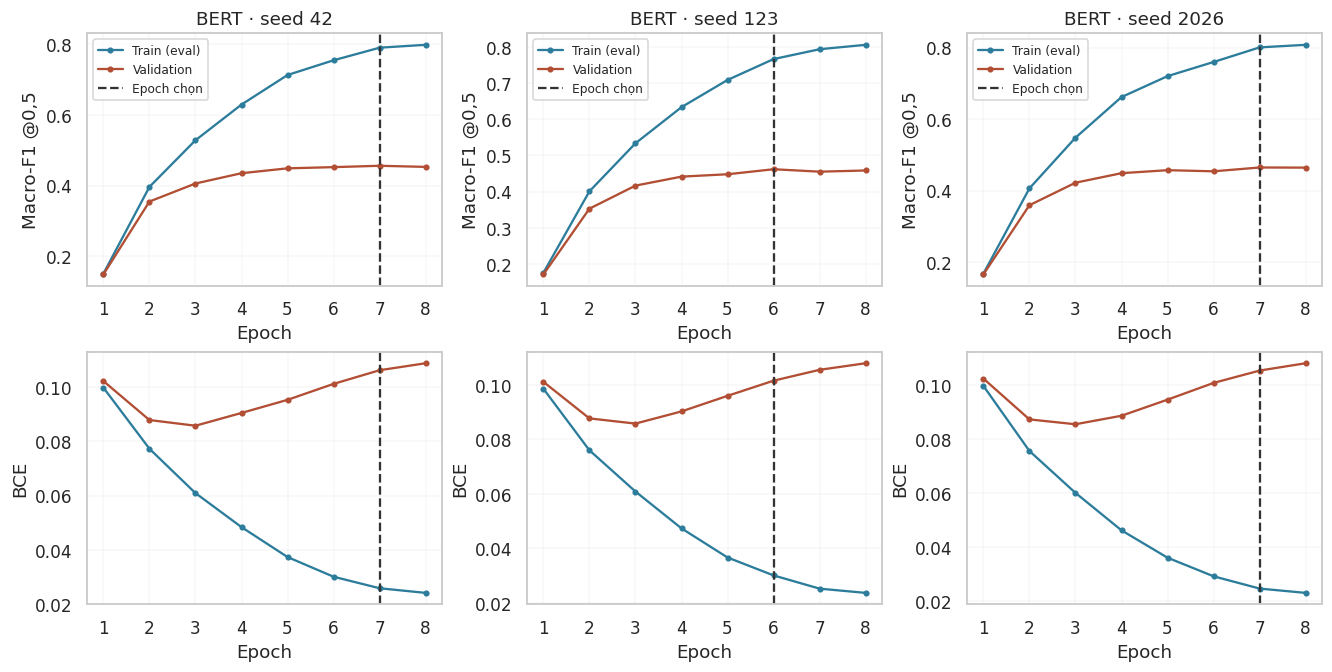

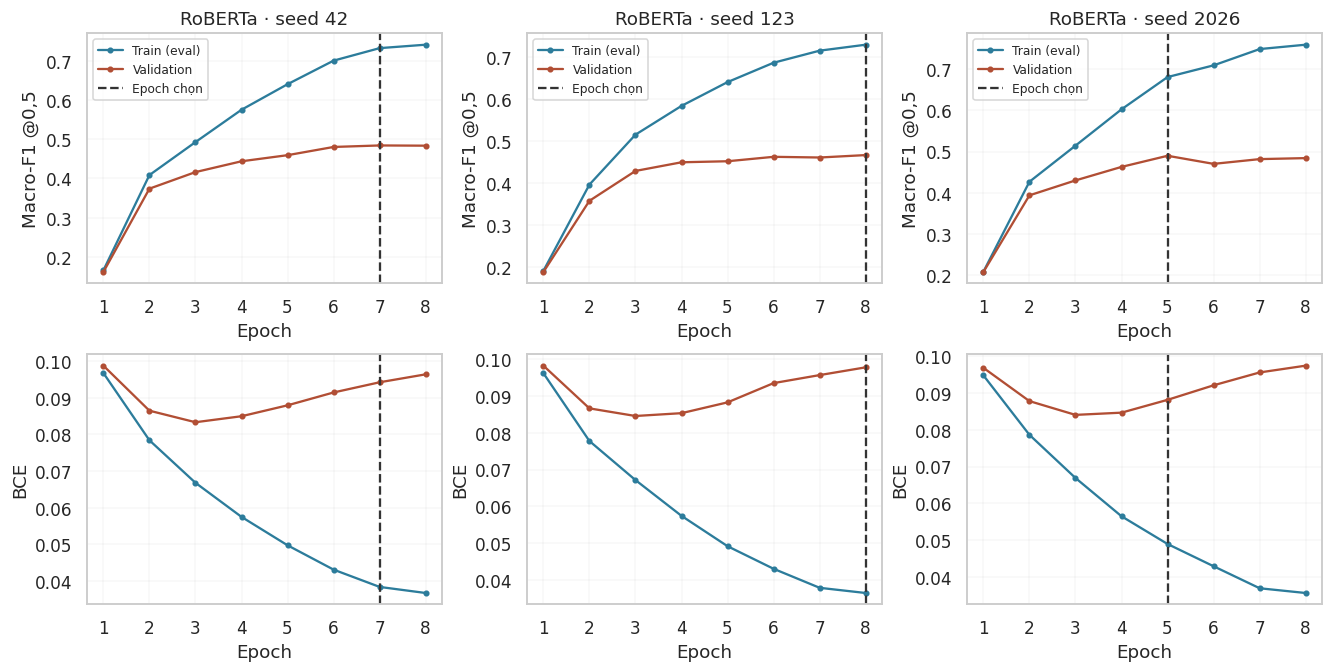

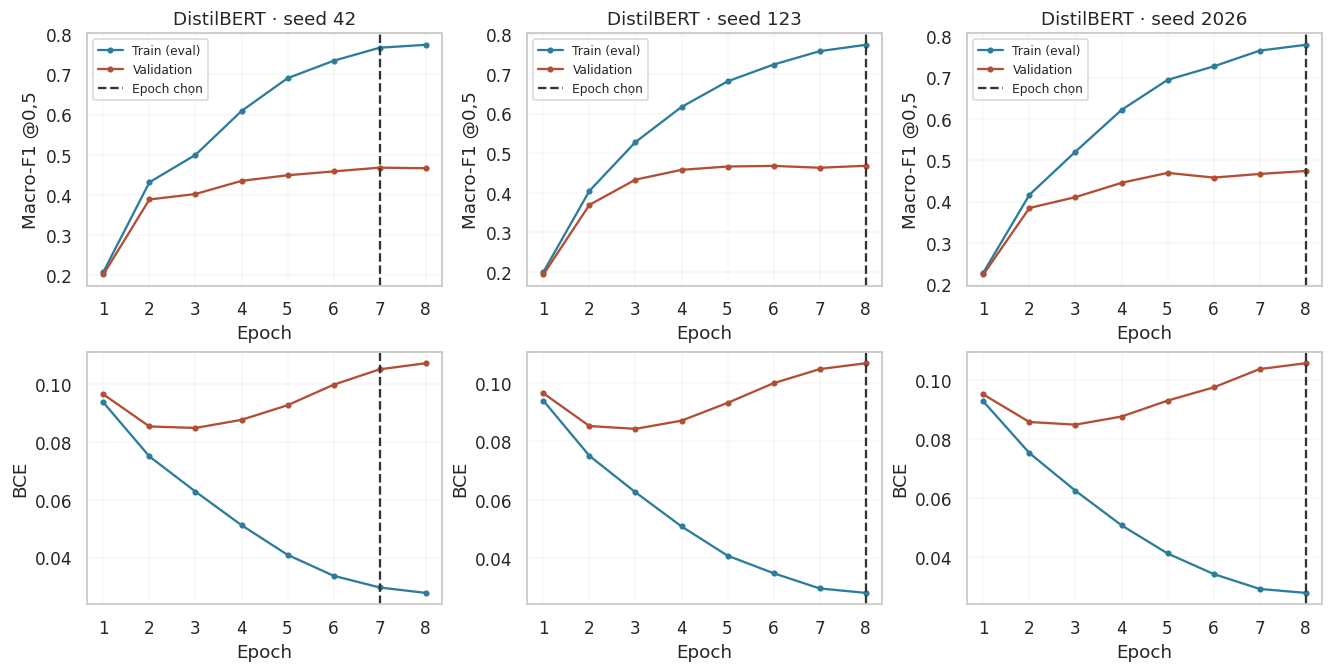

Đường được vẽ lại từ CSV 72 epoch, dấu dọc là checkpoint đã khóa.


In [55]:
history=pd.read_csv(ROOT/'sweep_log.csv')
chosen=history[history.selected==1][['model','seed','epoch','val_macro_f1','val_bce']]
assert len(history)==72 and len(chosen)==9
display(chosen.round(6))
for name in ['BERT','RoBERTa','DistilBERT']:
    fig=charts.learning_curves(history,name);plt.show();plt.close(fig)
print('Đường được vẽ lại từ CSV 72 epoch, dấu dọc là checkpoint đã khóa.')

## 4. Kiểm tra overfit với checkpoint ban đầu
Đối chiếu trên toàn bộ train/validation, cùng eval mode, AMP fp16 và batch16. C2/C3 có mốc ba epoch thực tế; BERT cũ là bốn epoch và learning rate khác. Đây là chẩn đoán sau huấn luyện, không dùng test để chọn lại epoch.

,architecture,seed,original_epochs,selected_epoch,old_gap_macro_f1,selected_gap_macro_f1,old_val_bce,selected_val_bce,selected_minus_original_saved_val_f1
0,bert,42,4,7,0.264199,0.333544,0.094315,0.106145,-0.008179
1,bert,123,4,6,0.250426,0.304761,0.091837,0.101499,-0.015357
2,bert,2026,4,7,0.249484,0.336083,0.093245,0.105355,-0.007850
3,roberta,42,3,7,0.059863,0.247892,0.083892,0.094248,0.055536
4,roberta,123,3,8,0.063906,0.263011,0.083959,0.097775,0.055385
5,roberta,2026,3,5,0.067250,0.190798,0.083688,0.088151,0.059174
6,distilbert,42,3,7,0.069215,0.298411,0.084445,0.105085,0.066173
7,distilbert,123,3,8,0.065563,0.306095,0.084083,0.106701,0.054892
8,distilbert,2026,3,8,0.069229,0.305243,0.084298,0.105625,0.069806


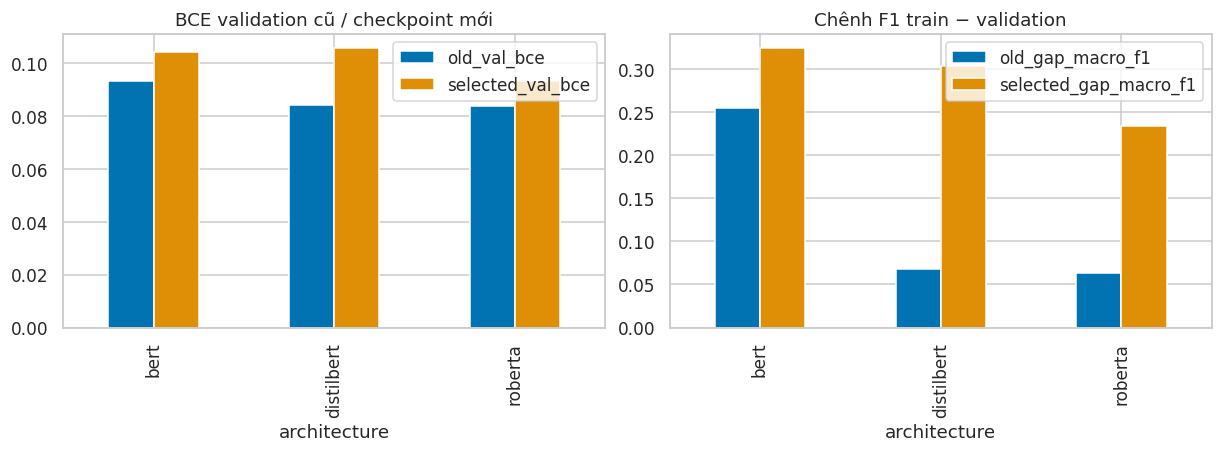

BERT: gap Macro-F1 train–validation tại checkpoint ban đầu là 0,2547 ± 0,0082, tại checkpoint được chọn trong ngân sách tám epoch là 0,3248 ± 0,0174. BCE validation đo cùng AMP thay đổi từ 0,0931 ± 0,0012 sang 0,1043 ± 0,0025. Trong lịch tám epoch, 3/3 seed có BCE train giảm nhưng BCE validation tăng từ epoch 3 đến epoch 8. Đây là dấu hiệu quá khớp theo loss cần đọc cùng F1, không phải bằng chứng rằng mọi tiêu chí đều kém đi. Macro-F1 validation tại checkpoint chọn chênh trung bình -0,0105 so với giá trị đã lưu của lượt ban đầu. Mốc BERT ban đầu là bốn epoch với learning rate khác, nên không gọi đây là so sánh chỉ thay từ ba lên tám epoch.
RoBERTa: gap Macro-F1 train–validation tại checkpoint ban đầu là 0,0637 ± 0,0037, tại checkpoint được chọn trong ngân sách tám epoch là 0,2339 ± 0,0381. BCE validation đo cùng AMP thay đổi từ 0,0838 ± 0,0001 sang 0,0934 ± 0,0049. Trong lịch tám epoch, 3/3 seed có BCE train giảm nhưng BCE validation tăng từ epoch 3 đến epoch 8. Đây là dấu hiệu quá khớ

In [56]:
audit = pd.read_csv(ROOT / "overfit_audit/overfit_comparison.csv")
display(audit[["architecture", "seed", "original_epochs", "selected_epoch", "old_gap_macro_f1", "selected_gap_macro_f1", "old_val_bce", "selected_val_bce", "selected_minus_original_saved_val_f1"]].round(6))
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
group=audit.groupby('architecture')[['old_train_bce','old_val_bce','selected_train_bce','selected_val_bce','old_gap_macro_f1','selected_gap_macro_f1']].mean()
group[['old_val_bce','selected_val_bce']].plot.bar(ax=axes[0],title='BCE validation cũ / checkpoint mới')
group[['old_gap_macro_f1','selected_gap_macro_f1']].plot.bar(ax=axes[1],title='Chênh F1 train − validation')
plt.show();plt.close(fig)
for model in read(ROOT / "overfit_audit/summary.json")["models"]:
    print(model["interpretation"])

## So sánh test trước và sau
Bảng này mô tả kết quả sau khóa. Không dùng nó để chọn lại checkpoint. Cần đọc đồng thời Macro-F1, Micro-F1 và Hamming Loss.

In [57]:
before_after = pd.read_csv(MAIN / "report_data/test_before_after.csv")
display(before_after[before_after["mode"] == "tuned"].round(6))
print("Macro-F1 C2/C3 tăng, nhưng Micro-F1 cả ba giảm và Hamming Loss tăng; BERT còn thay learning rate so với lượt cũ.")

,architecture,mode,old_epoch_budget,old_learning_rate,new_epoch_budget,new_learning_rate,selected_epochs_42_123_2026,old_macro_f1_mean,old_macro_f1_std,new_macro_f1_mean,new_macro_f1_std,delta_macro_f1,old_micro_f1_mean,old_micro_f1_std,new_micro_f1_mean,new_micro_f1_std,delta_micro_f1,old_hamming_loss_mean,old_hamming_loss_std,new_hamming_loss_mean,new_hamming_loss_std,delta_hamming_loss
1,bert,tuned,4,0.000050,8,0.000020,7/6/7,0.503752,0.009682,0.493794,0.007451,-0.009958,0.590001,0.002851,0.571725,0.005126,-0.018275,0.037259,0.000338,0.040450,0.001581,0.003192
3,roberta,tuned,3,0.000020,8,0.000020,7/8/5,0.487201,0.015562,0.510117,0.007619,0.022916,0.604847,0.005666,0.590873,0.003315,-0.013975,0.036460,0.001366,0.037713,0.000226,0.001253
5,distilbert,tuned,3,0.000020,8,0.000020,7/8/8,0.486632,0.009338,0.497209,0.002687,0.010577,0.593544,0.004748,0.577897,0.006898,-0.015647,0.037732,0.000958,0.038919,0.001188,0.001187


Macro-F1 C2/C3 tăng, nhưng Micro-F1 cả ba giảm và Hamming Loss tăng; BERT còn thay learning rate so với lượt cũ.


## 5. Giới hạn diễn giải
Cả ba C trong bảng chính dùng LR 2×10⁻⁵, ngân sách tám epoch và checkpoint chọn riêng từng seed. Phép đối chiếu BERT với lượt cũ đồng thời thay LR và số epoch. Test đã từng được xem ở phiên bản báo cáo trước; đây không phải holdout mới. Không dùng số test để tinh chỉnh tiếp.

## Bảng B.3 — test của các lượt chạy ban đầu
Bảng giữ số cũ với cấu hình khác để đối chiếu, không thay bảng kết quả chính. BERT cũ có LR5e-5/bốn epoch; C2/C3 có LR2e-5/ba epoch. Không dùng cấu hình khác nhau để kết luận riêng về kiến trúc.

In [58]:
historical = pd.read_csv(MAIN / "report_data/original_test_summary.csv")
assert len(historical) == 6
columns = ["system", "threshold_mode", "macro_f1_mean", "macro_f1_std", "micro_f1_mean", "micro_f1_std", "hamming_loss_mean", "hamming_loss_std"]
display(historical[columns].round(4))
context = read(ROOT / "report_context.json")
print(context["reason"])
print(context["test_history"])
print(context["demo_limitation"])

,system,threshold_mode,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,hamming_loss_mean,hamming_loss_std
0,C_bert,fixed,0.472000,0.004500,0.582000,0.004000,0.031800,0.000300
1,C_bert,tuned,0.503800,0.009700,0.590000,0.002900,0.037300,0.000300
2,C_roberta,fixed,0.421900,0.008800,0.580300,0.000900,0.029500,0.000100
3,C_roberta,tuned,0.487200,0.015600,0.604800,0.005700,0.036500,0.001400
4,C_distilbert,fixed,0.411600,0.003500,0.573100,0.001700,0.029700,0.000100
5,C_distilbert,tuned,0.486600,0.009300,0.593500,0.004700,0.037700,0.001000


Bảng kết quả chính giữ cùng learning rate 2×10⁻⁵ và ngân sách tám epoch cho ba kiến trúc để hạn chế khác biệt về hai cài đặt này, không chọn cấu hình tốt nhất riêng cho từng mô hình. Vì vậy BERT trong bảng chính có Macro-F1 ngưỡng riêng 0,4938, thấp hơn 0,5038 ở lượt chạy ban đầu (Bảng B.3). Ngân sách tám epoch nằm trong kế hoạch kiểm tra giả thuyết C2/C3 học chưa đủ ở cấu hình ba epoch, đồng thời theo dõi F1 và BCE. Tám epoch là phạm vi khảo sát, chưa được chứng minh tối ưu chung.
Lịch tám epoch được quyết định sau khi nhóm đã xem kết quả test của các lượt chạy ban đầu (xem mục 6.2); các lựa chọn của bộ hiện tại (checkpoint, đại diện, ngưỡng) được khóa bằng validation trước đánh giá test.
Demo hiện chạy cục bộ; chưa có đường dẫn demo công khai để truy cập từ máy khác. Mã nguồn và gói checkpoint đã được công bố để tải và chạy lại ứng dụng.


## Kiểm độc lập các bảng báo cáo
Chạy `python experiments/best_epochs_20261103/verify_report_tables.py` từ gốc repository. Lệnh tính lại từ điểm dự đoán và đối chiếu cả bảng lịch sử; không huấn luyện lại.

# Phần 7. Ba ngưỡng, nhãn hiếm và lỗi — Chương 5

# 05 · Ngưỡng và phân tích lỗi — báo cáo IEEE v8
Đối chiếu Bảng 5.6, 5.13–5.17, Phụ lục D/E và PPT slide 23/32/33. Mỗi phần có bảng và kết quả tính trực tiếp. Không huấn luyện hoặc chọn lại ngưỡng theo test. A/B một lượt; mỗi C đủ ba seed.

In [59]:
from pathlib import Path
import importlib.util, json
import numpy as np
import pandas as pd
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "experiments/threshold_error_20261110/analysis.py").exists())
folder = root / "experiments/threshold_error_20261110"
spec = importlib.util.spec_from_file_location("threshold_analysis", folder / "analysis.py")
a = importlib.util.module_from_spec(spec); spec.loader.exec_module(a)
a.ensure_inputs("validation")
lock = a.read(folder / "validation_lock.json")
receipt = a.read(folder / "results/verification.json")
assert receipt["validation_lock_sha256"] == a.sha(folder / "validation_lock.json")
print("11 bộ kết quả; ba seed cho mỗi C, một lượt cho A và B.")
import sys
if str(root) not in sys.path:sys.path.insert(0,str(root))
import matplotlib.pyplot as plt
from src import report_figures as charts

11 bộ kết quả; ba seed cho mỗi C, một lượt cho A và B.


## 1. Kiểm toán lại validation
Điểm phải đúng ID và thứ tự 28 nhãn. Ngưỡng tính lại cần khớp bản đã khóa; nếu khác, dừng và không thay ngưỡng theo test.

In [60]:
vf = pd.read_parquet(root / lock["validation_data"])
vy = a.targets(vf)
audits=[]
for run in lock["checkpoints"]:
    assert a.sha(root / run["val_scores"]) == run["validation_scores_sha256"]
    vs = a.load_scores(root / run["val_scores"], vf, lock["label_names"])
    thresholds, global_t, _ = a.select(vs, vy)
    different = int((np.abs(thresholds - np.array(run["thresholds"])) > 1e-6).sum())
    assert different == 0 and abs(global_t - run["global_threshold"]) < 1e-6
    audits.append({"model": run["model"], "seed": run["seed"], "khac_nguong": different, "nguong_chung": global_t})
display(pd.DataFrame(audits))

,model,seed,khac_nguong,nguong_chung
0,C1 BERT,42.000000,0,0.200000
1,C1 BERT,123.000000,0,0.200000
2,C1 BERT,2026.000000,0,0.250000
3,C2 RoBERTa,42.000000,0,0.400000
4,C2 RoBERTa,123.000000,0,0.250000
5,C2 RoBERTa,2026.000000,0,0.250000
6,C3 DistilBERT,42.000000,0,0.200000
7,C3 DistilBERT,123.000000,0,0.200000
8,C3 DistilBERT,2026.000000,0,0.100000
9,A TF-IDF balanced,42.000000,0,0.550000


## 2. Tái hiện đủ ba chế độ trên test
Đây là đánh giá các lựa chọn đã khóa. Không dùng kết quả để chọn lại chế độ, epoch hay mô hình.

,model,mode,n_runs,macro_f1_mean,macro_f1_std,micro_f1_mean,hamming_mean
0,C1 BERT,fixed,3,0.469636,0.005473,0.570629,0.033356
1,C1 BERT,global,3,0.479374,0.003752,0.566296,0.040170
2,C1 BERT,tuned,3,0.493794,0.007451,0.571725,0.040450
3,C2 RoBERTa,fixed,3,0.476459,0.007916,0.574146,0.032523
4,C2 RoBERTa,global,3,0.498482,0.012112,0.580268,0.037164
5,C2 RoBERTa,tuned,3,0.510117,0.007619,0.590873,0.037713
6,C3 DistilBERT,fixed,3,0.472875,0.003889,0.570709,0.032876
7,C3 DistilBERT,global,3,0.488286,0.005534,0.562286,0.043587
8,C3 DistilBERT,tuned,3,0.497209,0.002687,0.577897,0.038919
9,A TF-IDF balanced,fixed,1,0.444052,NaN,0.502364,0.054720


Khớp 33/33 bộ metric từ điểm dự đoán thật.


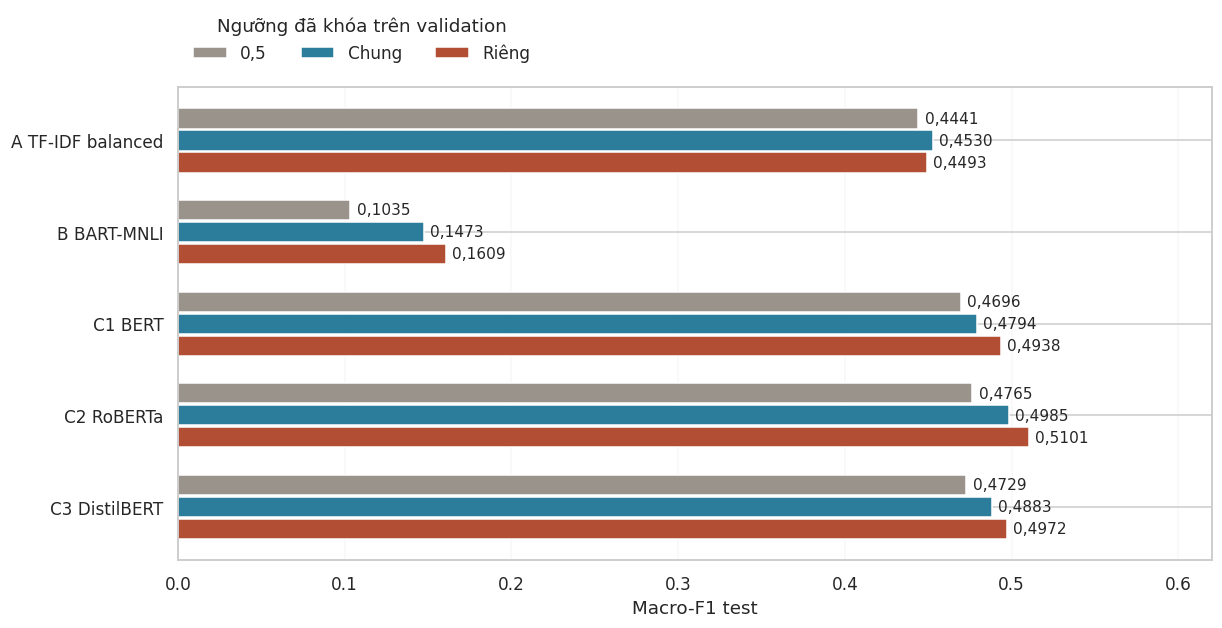

A là phản ví dụ: ngưỡng chung có Macro-F1 cao hơn ngưỡng riêng. Không chọn lại bằng test.


In [61]:
a.ensure_inputs("test")
tf = pd.read_parquet(a.OLD / "main_results/data/raw/test-00000-of-00001.parquet")
ty = a.targets(tf)
saved = pd.read_csv(folder / "results/modes_per_checkpoint.csv")
checks = 0
for run in lock["checkpoints"]:
    ts = a.load_scores(root / run["test_scores"], tf, lock["label_names"])
    for mode, thresholds in {"fixed": .5, "global": run["global_threshold"], "tuned": np.array(run["thresholds"])}.items():
        actual = a.metrics(ty, ts >= thresholds)
        rows = saved[(saved.model == run["model"]) & (saved["mode"] == mode)]
        rows = rows[rows.seed.isna()] if run["seed"] is None else rows[rows.seed == run["seed"]]
        assert len(rows) == 1
        for key, value in actual.items():
            assert abs(value - rows.iloc[0][key]) < 1e-12, (run["model"], mode, key)
        checks += 1
summary = pd.read_csv(folder / "results/modes_mean_std.csv")
assert checks == 33
display(summary[["model","mode","n_runs","macro_f1_mean","macro_f1_std","micro_f1_mean","hamming_mean"]])
print("Khớp 33/33 bộ metric từ điểm dự đoán thật.")
fig=charts.threshold_modes(summary);plt.show();plt.close(fig)
print("A là phản ví dụ: ngưỡng chung có Macro-F1 cao hơn ngưỡng riêng. Không chọn lại bằng test.")

A đạt Macro-F1 ngưỡng chung cao hơn ngưỡng riêng. Ba C có Macro-F1 ngưỡng riêng cao hơn nhưng Hamming Loss và exact match có thể xấu đi. Std là độ lệch chuẩn mẫu giữa ba seed, không phải khoảng tin cậy.

## 3. Năm loại câu loại trừ nhau và giao ba tập lỗi cũ

model,C1 BERT,C2 RoBERTa,C3 DistilBERT
category,,,
doan_sai_nhan,1763,1548,1607
doan_thua,236,165,247
dung_hoan_toan,2540,2526,2476
dung_mot_phan,507,497,493
khong_doan_gi,381,691,604


,model,g1,g2,g3,g1_and_g2,g1_and_g3,g2_and_g3,all_three,union
6,C1 BERT,507,71,1813,19,50,35,1,2288
15,C2 RoBERTa,497,69,1582,21,34,27,0,2066
24,C3 DistilBERT,493,68,1650,17,43,24,0,2127


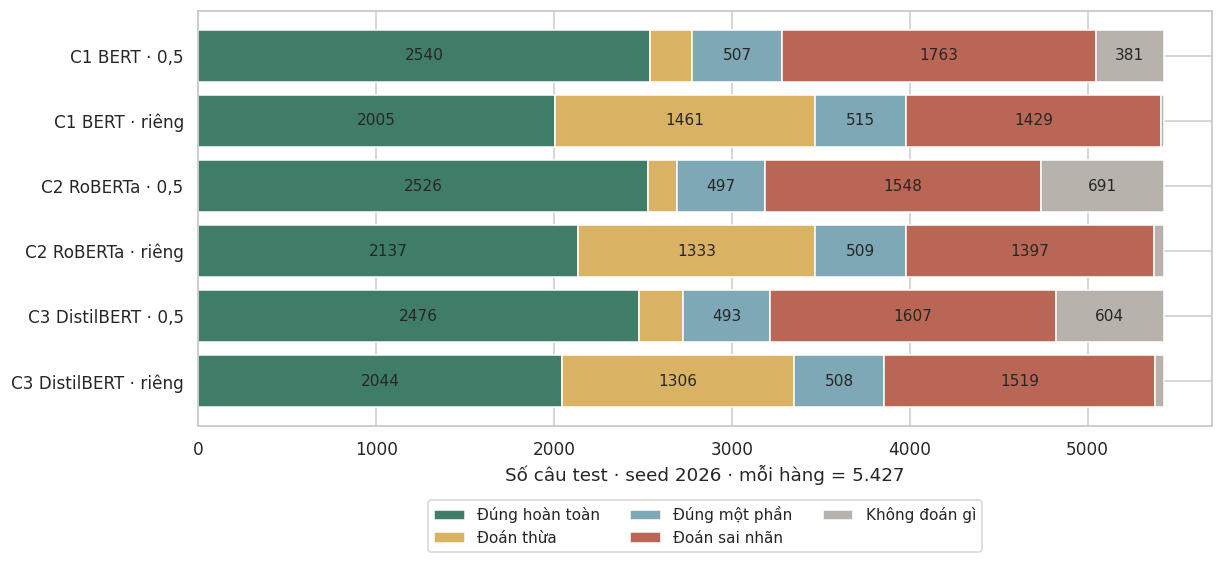

In [62]:
tax = pd.read_csv(folder / "results/error_taxonomy.csv")
assert (tax.groupby(["model","seed","mode"], dropna=False).n.sum() == 5427).all()
overlap = pd.read_csv(folder / "results/error_overlap.csv")
union = overlap.g1 + overlap.g2 + overlap.g3 - overlap.g1_and_g2 - overlap.g1_and_g3 - overlap.g2_and_g3 + overlap.all_three
assert (union == overlap["union"]).all()
assert (overlap[[f"only_mask_{i}" for i in range(1,8)]].sum(axis=1) == union).all()
display(tax[(tax.seed==2026)&(tax["mode"]=="fixed")].pivot(index="category",columns="model",values="n"))
display(overlap[(overlap.seed==2026)&(overlap["mode"]=="fixed")][["model","g1","g2","g3","g1_and_g2","g1_and_g3","g2_and_g3","all_three","union"]])
fig=charts.exclusive_errors(tax);plt.show();plt.close(fig)

## 4. Toàn bộ ngưỡng, support và lỗi gần ngưỡng

C1 BERT — đủ 28 ngưỡng theo ba seed:


seed,42.000000,123.000000,2026.000000
label,,,
admiration,0.500000,0.350000,0.450000
amusement,0.500000,0.400000,0.500000
anger,0.400000,0.600000,0.350000
annoyance,0.150000,0.150000,0.100000
approval,0.200000,0.150000,0.350000
caring,0.300000,0.650000,0.300000
confusion,0.250000,0.400000,0.450000
curiosity,0.300000,0.150000,0.150000
desire,0.450000,0.400000,0.250000


C2 RoBERTa — đủ 28 ngưỡng theo ba seed:


seed,42.000000,123.000000,2026.000000
label,,,
admiration,0.400000,0.350000,0.450000
amusement,0.600000,0.300000,0.450000
anger,0.300000,0.400000,0.350000
annoyance,0.200000,0.250000,0.200000
approval,0.450000,0.300000,0.250000
caring,0.550000,0.150000,0.300000
confusion,0.500000,0.250000,0.250000
curiosity,0.150000,0.100000,0.350000
desire,0.400000,0.250000,0.450000


C3 DistilBERT — đủ 28 ngưỡng theo ba seed:


seed,42.000000,123.000000,2026.000000
label,,,
admiration,0.500000,0.550000,0.500000
amusement,0.200000,0.150000,0.300000
anger,0.300000,0.350000,0.750000
annoyance,0.250000,0.300000,0.100000
approval,0.200000,0.300000,0.200000
caring,0.200000,0.300000,0.450000
confusion,0.350000,0.500000,0.500000
curiosity,0.150000,0.150000,0.050000
desire,0.400000,0.400000,0.300000


model,A TF-IDF balanced,B BART-MNLI
label,,
admiration,0.550000,0.950000
amusement,0.600000,0.950000
anger,0.600000,0.950000
annoyance,0.450000,0.950000
approval,0.600000,0.950000
caring,0.650000,0.950000
confusion,0.650000,0.950000
curiosity,0.700000,0.950000
desire,0.800000,0.950000


low  high
model             seed                  
A TF-IDF balanced 42.000000      0     0
B BART-MNLI       NaN            1    26
C1 BERT           42.000000      3     0
                  123.000000     0     0
                  2026.000000    4     0
C2 RoBERTa        42.000000      1     0
                  123.000000     1     0
                  2026.000000    2     0
C3 DistilBERT     42.000000      1     0
                  123.000000     0     0
                  2026.000000    1     0

B có 26/28 ngưỡng riêng ở 0,95. Chỉ tối ưu trong lưới đã khóa, chưa chứng minh tối ưu toàn [0,1]. Không mở lưới sau khi xem test.


,model,type,n,share_ratio_ge_0_8,share_margin_le_0_1
16,C1 BERT,FN,2137,0.059897,NaN
17,C1 BERT,FP,4201,NaN,0.282076
34,C2 RoBERTa,FN,2145,0.098834,NaN
35,C2 RoBERTa,FP,3558,NaN,0.276560
52,C3 DistilBERT,FN,2275,0.073407,NaN
53,C3 DistilBERT,FP,3838,NaN,0.264721


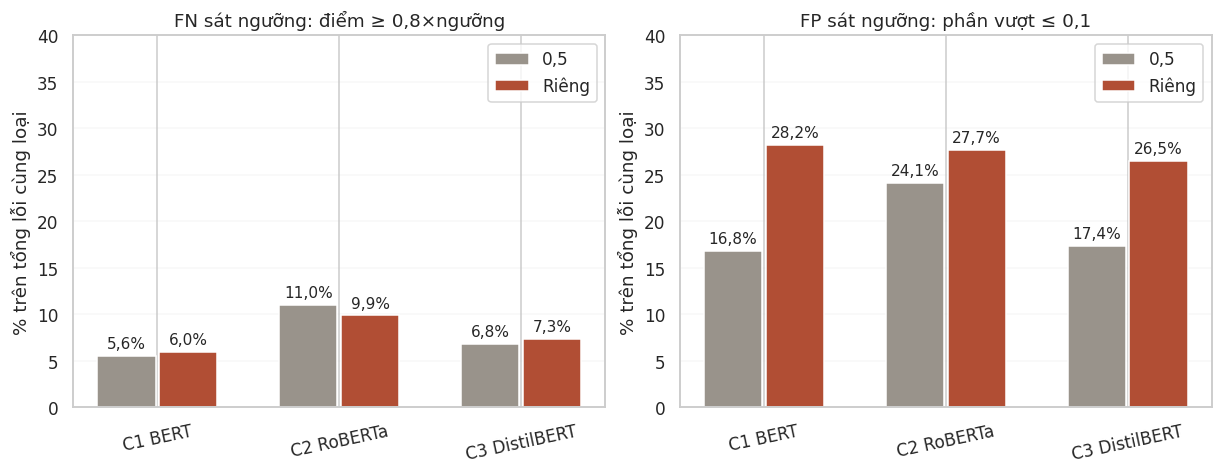

In [63]:
thresholds=pd.read_csv(folder/'results/thresholds_28.csv')
assert len(thresholds)==11*28
for model in ['C1 BERT','C2 RoBERTa','C3 DistilBERT']:
    table=thresholds[thresholds.model==model]
    print(model,'— đủ 28 ngưỡng theo ba seed:')
    display(table.pivot(index='label',columns='seed',values='threshold_label'))
single=thresholds[thresholds.model.isin(['A TF-IDF balanced','B BART-MNLI'])]
display(single.pivot(index='label',columns='model',values='threshold_label'))
boundary=thresholds.assign(low=thresholds.threshold_label.eq(.05),high=thresholds.threshold_label.eq(.95)).groupby(['model','seed'],dropna=False)[['low','high']].sum()
display(boundary)
print('B có 26/28 ngưỡng riêng ở 0,95. Chỉ tối ưu trong lưới đã khóa, chưa chứng minh tối ưu toàn [0,1]. Không mở lưới sau khi xem test.')
near=pd.read_csv(folder/'results/near_miss.csv')
display(near[(near.seed==2026)&(near['mode']=='tuned')][['model','type','n','share_ratio_ge_0_8','share_margin_le_0_1']])
fig=charts.near_miss(near);plt.show();plt.close(fig)

Near-miss chỉ mô tả vị trí lỗi so với ngưỡng đã khóa. FN sát ngưỡng: điểm ≥0,8×ngưỡng; FP sát ngưỡng: phần vượt ≤0,1. Không dùng bảng này để đổi ngưỡng theo test.

## 5. Kiểm số ví dụ caring/optimism và bảng epoch

In [64]:
display(pd.read_csv(folder / "results/caring_optimism_verified.csv"))
sweep = pd.read_csv(a.OLD / "sweep_log.csv")
assert len(sweep) == 72
chosen = sweep.sort_values(["val_macro_f1","epoch"],ascending=[False,True]).groupby(["model","seed"],sort=False).head(1)
display(chosen[["model","seed","epoch","val_macro_f1","val_bce"]].sort_values(["model","seed"]))
print("BCE validation thấp nhất:")
display(sweep.sort_values(["val_bce","epoch"]).groupby(["model","seed"]).head(1)[["model","seed","epoch","val_bce"]])

,model,seed,mode,id,caring,optimism,truth,prediction
0,C1 BERT,2026,fixed,eeq65gb,0.902438,0.260389,caring|optimism,caring
1,C1 BERT,2026,tuned,eeq65gb,0.902438,0.260389,caring|optimism,caring
2,C2 RoBERTa,2026,fixed,eeq65gb,0.910067,0.077100,caring|optimism,caring
3,C2 RoBERTa,2026,tuned,eeq65gb,0.910067,0.077100,caring|optimism,caring
4,C3 DistilBERT,2026,fixed,eeq65gb,0.862930,0.369429,caring|optimism,caring
5,C3 DistilBERT,2026,tuned,eeq65gb,0.862930,0.369429,caring|optimism,caring|optimism


,model,seed,epoch,val_macro_f1,val_bce
6,BERT,42,7,0.455969,0.106145
13,BERT,123,6,0.461938,0.101499
22,BERT,2026,7,0.464495,0.105355
54,DistilBERT,42,7,0.468009,0.105085
63,DistilBERT,123,8,0.468118,0.106701
71,DistilBERT,2026,8,0.473971,0.105625
30,RoBERTa,42,7,0.484181,0.094248
39,RoBERTa,123,8,0.466438,0.097775
44,RoBERTa,2026,5,0.489797,0.088151


BCE validation thấp nhất:


,model,seed,epoch,val_bce
26,RoBERTa,42,3,0.083334
42,RoBERTa,2026,3,0.084064
58,DistilBERT,123,3,0.084258
34,RoBERTa,123,3,0.084559
50,DistilBERT,42,3,0.084808
66,DistilBERT,2026,3,0.084857
18,BERT,2026,3,0.085459
2,BERT,42,3,0.085709
10,BERT,123,3,0.085765


## 6. Mẫu đọc độc lập — Bảng 5.19

Bản v8 chọn 50 mục câu–cặp lỗi từ khung 145 mục. Hai người đọc cùng mẫu, mỗi người điền phiếu riêng. Các mã nhận định và độ đồng thuận cần hai phiếu hoàn tất.

In [65]:
from experiments.report_v8.verify_tables import annotation_sample

read_sample = annotation_sample()
display(read_sample.groupby('pair').size().rename('số mục').to_frame())


,số mục
pair,
neutral->approval,48
relief->admiration,2


## 7. F1 của năm nhãn hiếm — Word Bảng 5.9, PPT slide 28
Mỗi nhãn được tính mean và std mẫu trên đủ ba seed. Đồ thị dùng đúng thứ tự grief/pride/relief/nervousness/embarrassment; không bỏ nhãn bị giảm F1.

,model,label,mode,mean,std
0,C1 BERT,embarrassment,fixed,0.494525,0.012629
1,C1 BERT,embarrassment,tuned,0.479353,0.036536
2,C1 BERT,grief,fixed,0.000000,0.000000
3,C1 BERT,grief,tuned,0.114286,0.103016
4,C1 BERT,nervousness,fixed,0.305964,0.024780
5,C1 BERT,nervousness,tuned,0.305263,0.034557
6,C1 BERT,pride,fixed,0.183465,0.057299
7,C1 BERT,pride,tuned,0.457986,0.078811
8,C1 BERT,relief,fixed,0.000000,0.000000
9,C1 BERT,relief,tuned,0.265416,0.007875


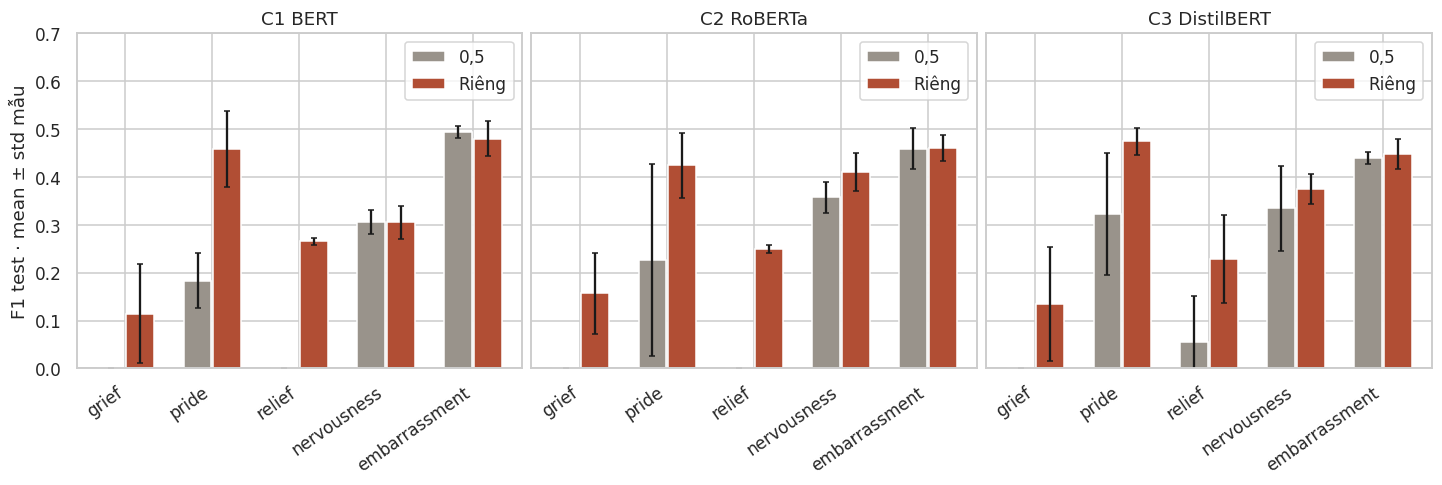

grief chỉ có 6 mẫu test. F1 nhãn hiếm có thể dao động mạnh; giữ cả nhãn bị giảm.


In [66]:
per_label=pd.read_csv(folder/'results/label_tpfpfn.csv')
rare=['grief','pride','relief','nervousness','embarrassment']
data=per_label[per_label.model.str.startswith('C') & per_label.label.isin(rare) & per_label['mode'].isin(['fixed','tuned'])]
rare_c=data.groupby(['model','label','mode']).f1.agg(['mean','std']).reset_index()
display(rare_c)
fig,axes=plt.subplots(1,3,figsize=(13,4.3),layout='constrained',sharey=True)
for ax,model in zip(axes,['C1 BERT','C2 RoBERTa','C3 DistilBERT']):
    for i,mode in enumerate(['fixed','tuned']):
        rows=rare_c[(rare_c.model==model)&(rare_c['mode']==mode)].set_index('label').loc[rare]
        ax.bar(np.arange(5)+(i-.5)*.34,rows['mean'],yerr=rows['std'],width=.32,capsize=2,label='0,5' if mode=='fixed' else 'Riêng',color='#99938B' if mode=='fixed' else '#B14E34')
    ax.set_xticks(np.arange(5),rare,rotation=35,ha='right');ax.set_title(model);ax.set_ylim(0,.7);ax.legend()
axes[0].set_ylabel('F1 test · mean ± std mẫu');plt.show();plt.close(fig)
print('grief chỉ có 6 mẫu test. F1 nhãn hiếm có thể dao động mạnh; giữ cả nhãn bị giảm.')

## 8. Ma trận FN→FP từ điểm thật — Word Phụ lục C / PPT slide 19
Tính ở **seed 2026, ngưỡng 0,5** để khớp slide. Hàng là nhãn bị bỏ sót, cột là nhãn thêm sai trong cùng câu. Một câu có thể đóng góp nhiều cặp; đây không phải confusion matrix đơn nhãn và không chứng minh nguyên nhân.

,neutral,approval,annoyance,disapproval,admiration
C1 BERT,,,,,
neutral,0,89,66,75,46
approval,81,0,5,8,17
annoyance,66,14,0,21,4
disapproval,55,4,11,0,5
admiration,21,19,3,2,0


,neutral,approval,annoyance,disapproval,admiration
C2 RoBERTa,,,,,
neutral,0,71,41,71,68
approval,53,0,3,9,23
annoyance,43,8,0,23,4
disapproval,42,3,6,0,6
admiration,16,11,1,1,0


,neutral,approval,annoyance,disapproval,admiration
C3 DistilBERT,,,,,
neutral,0,80,52,59,53
approval,80,0,3,14,18
annoyance,71,9,0,17,5
disapproval,66,1,12,0,5
admiration,24,16,0,4,0


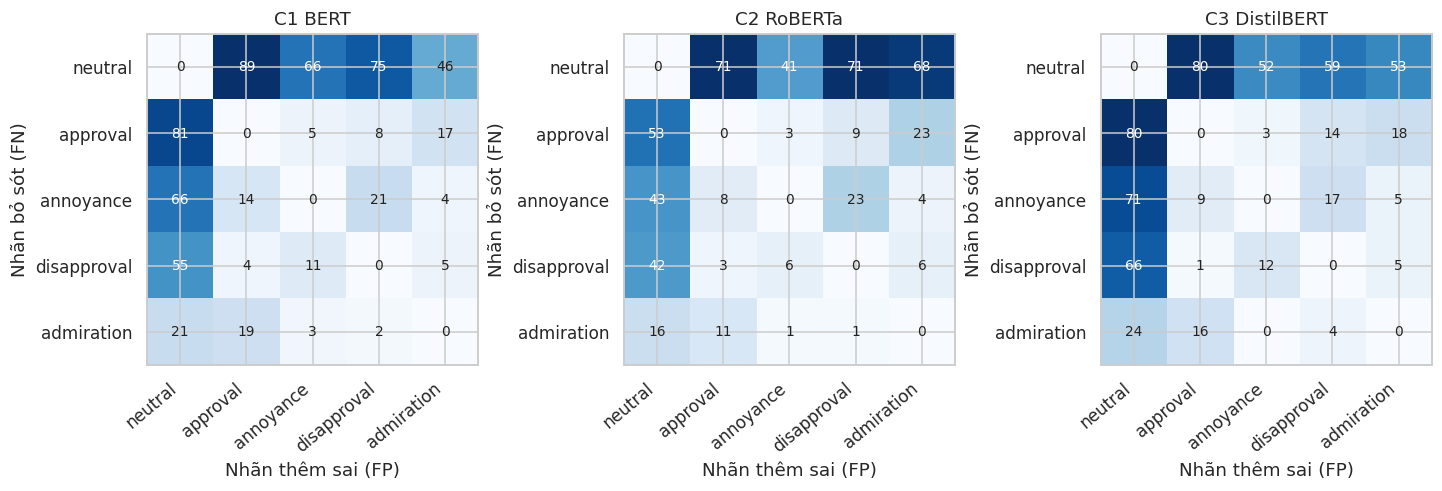

PASS: BERT neutral→approval = 89 ở ngưỡng 0,5, khớp slide 19. Bảng 5.15 dùng ngưỡng riêng, không trộn hai chế độ.


In [67]:
focus=['neutral','approval','annoyance','disapproval','admiration']
indices=[lock['label_names'].index(label) for label in focus]
fig,axes=plt.subplots(1,3,figsize=(13,4.3),layout='constrained')
for ax,model in zip(axes,['C1 BERT','C2 RoBERTa','C3 DistilBERT']):
    run=next(r for r in lock['checkpoints'] if r['model']==model and r['seed']==2026)
    points=a.load_scores(root/run['test_scores'],tf,lock['label_names']);prediction=points>=.5
    fn=ty & ~prediction;fp=~ty & prediction
    matrix=fn.astype(np.int64).T@fp.astype(np.int64);np.fill_diagonal(matrix,0)
    small=matrix[np.ix_(indices,indices)]
    display(pd.DataFrame(small,index=focus,columns=focus).rename_axis(model))
    ax.imshow(small,cmap='Blues',vmin=0,vmax=max(1,small.max()))
    for i in range(5):
        for j in range(5):ax.text(j,i,str(small[i,j]),ha='center',va='center',color='white' if small[i,j]>.55*small.max() else '#222222',fontsize=9)
    ax.set_xticks(range(5),focus,rotation=40,ha='right');ax.set_yticks(range(5),focus);ax.set_title(model)
    ax.set_xlabel('Nhãn thêm sai (FP)');ax.set_ylabel('Nhãn bỏ sót (FN)')
    if model=='C1 BERT':assert int(small[0,1])==89
plt.show();plt.close(fig)
print('PASS: BERT neutral→approval = 89 ở ngưỡng 0,5, khớp slide 19. Bảng 5.15 dùng ngưỡng riêng, không trộn hai chế độ.')

# Phần 8. Ví dụ baseline nhỏ để tự thử — không phải benchmark

## Chạy thử baseline trên CPU

Dữ liệu **tự tạo**, 3 nhãn minh họa; không phải benchmark GoEmotions (28 nhãn).
Ví dụ này không tải dataset/checkpoint. Dùng đúng pipeline của `scripts/baseline/run_baseline.py` và metric chung. Xem `README.md`.

In [68]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from scripts.baseline.run_baseline import build_model
from src.evaluation.metrics import evaluate_multilabel
print("Đã nạp baseline minh họa 3 nhãn; đây không phải bảng test GoEmotions.")

Đã nạp baseline minh họa 3 nhãn; đây không phải bảng test GoEmotions.


## 1. Văn bản và multi-hot

Mỗi hàng có thể có nhiều giá trị 1. Tập validation dưới đây là các câu mới; TF-IDF chỉ học từ train.

In [69]:
labels = ['gratitude', 'joy', 'sadness']
train_texts = ['thank you happy', 'thank you friend', 'happy wonderful', 'happy today',
               'sad alone', 'sad today', 'thank you wonderful', 'happy thank you']
y_train = np.array([[1, 1, 0], [1, 0, 0], [0, 1, 0], [0, 1, 0],
                    [0, 0, 1], [0, 0, 1], [1, 0, 0], [1, 1, 0]])
val_texts = ['thank you', 'happy', 'sad', 'happy thank you']
y_val = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1], [1, 1, 0]])
pd.DataFrame(y_train, columns=labels).assign(text=train_texts)

,gratitude,joy,sadness,text
0,1,1,0,thank you happy
1,1,0,0,thank you friend
2,0,1,0,happy wonderful
3,0,1,0,happy today
4,0,0,1,sad alone
5,0,0,1,sad today
6,1,0,0,thank you wonderful
7,1,1,0,happy thank you


## 2. Huấn luyện

Gọi cùng `build_model` của baseline thật; số LR bằng số cột nhãn. Trong GoEmotions sẽ là 28, trong ví dụ này là 3. Dùng balanced để minh họa trọng số lớp.

In [70]:
model = build_model('balanced')
model.fit(train_texts, y_train)
print('Vocabulary chỉ học từ train:', model.named_steps['tfidf'].get_feature_names_out())
print('Số LR:', len(model.named_steps['classifier'].estimators_))

Vocabulary chỉ học từ train: ['happy' 'sad' 'thank' 'thank you' 'today' 'wonderful' 'you']
Số LR: 3


## 3. Điểm dự đoán và ngưỡng

`predict_proba` trả một điểm độc lập cho mỗi nhãn. Không dùng argmax. Ngưỡng 0.5 ở đây là cố định; notebook không tuning bằng tập validation minh họa.

In [71]:
scores = model.predict_proba(val_texts)
threshold = 0.5
predicted = scores >= threshold
view = pd.DataFrame(scores, columns=labels)
view['text'] = val_texts
view['predicted_labels'] = [[label for label, yes in zip(labels, row) if yes] for row in predicted]
view

,gratitude,joy,sadness,text,predicted_labels
0,0.723995,0.462213,0.311864,thank you,[gratitude]
1,0.429863,0.696233,0.353676,happy,[joy]
2,0.335360,0.339782,0.714537,sad,[sadness]
3,0.678125,0.575050,0.278914,happy thank you,"[gratitude, joy]"


## 4. Đánh giá bằng module chung

Các số dưới đây chỉ kiểm luồng code trên dữ liệu tự tạo. Không đưa vào bảng kết quả đồ án.

In [72]:
metrics = evaluate_multilabel(y_val, scores, labels, threshold=threshold)
pd.Series({name: metrics[name] for name in
           ['macro_f1', 'micro_f1', 'micro_precision', 'micro_recall', 'hamming_loss']})

macro_f1          1.000000
micro_f1          1.000000
micro_precision   1.000000
micro_recall      1.000000
hamming_loss      0.000000
dtype: float64

## 5. Tự thử một câu

Đổi câu tiếng Anh bên dưới rồi chạy lại. Với câu chứa từ ngoài vocabulary, mô hình không học được ý nghĩa mới từ câu đó.

In [73]:
text = 'happy thank you friend'
row = model.predict_proba([text])[0]
print(text)
print({label: round(float(score), 4) for label, score in zip(labels, row)})
print('Nhãn:', [label for label, score in zip(labels, row) if score >= threshold])

happy thank you friend
{'gratitude': 0.6781, 'joy': 0.5751, 'sadness': 0.2789}
Nhãn: ['gratitude', 'joy']


## 6. Chuyển sang GoEmotions

Xem lại Phần 1 (dữ liệu) và Phần 4 (baseline A) trong notebook này. Mã huấn luyện baseline nằm ở `scripts/baseline/run_baseline.py`. Train 43.410 / val 5.426 / test 5.427, giữ 28 nhãn. Khóa cấu hình/ngưỡng trước test. Ví dụ này không lưu đè model hoặc kết quả benchmark.

# Phần 9. Các bảng bổ sung trong IEEE v8

Tính lại lưới 19 mức của nhãn approval (Bảng 5.7/Phụ lục F), số TP/FP/FN (Bảng 5.8) và độ trễ đo được (Bảng 5.21/Phụ lục G). Cả ba phần đối chiếu với CSV đã công bố.

In [74]:
from experiments.report_v8.verify_tables import verify

approval, errors, speed, sample, (total, positives) = verify()
display(approval.round(4))
best = approval.loc[approval.f1.idxmax()]
print(f"Ngưỡng approval được chọn: {best.threshold:.2f}, F1 = {best.f1:.7f}.")


,threshold,tp,fp,fn,precision,recall,f1
0,0.050000,306,1186,91,0.205100,0.770800,0.324000
1,0.100000,247,714,150,0.257000,0.622200,0.363800
2,0.150000,218,510,179,0.299500,0.549100,0.387600
3,0.200000,196,388,201,0.335600,0.493700,0.399600
4,0.250000,179,307,218,0.368300,0.450900,0.405400
5,0.300000,161,263,236,0.379700,0.405500,0.392200
6,0.350000,149,214,248,0.410500,0.375300,0.392100
7,0.400000,140,180,257,0.437500,0.352600,0.390500
8,0.450000,131,152,266,0.462900,0.330000,0.385300
9,0.500000,119,129,278,0.479800,0.299700,0.369000


Ngưỡng approval được chọn: 0.25, F1 = 0.4054360.


## Vì sao accuracy dễ gây hiểu lầm và vì sao phải đọc FP/FN
Ví dụ dự đoán không nhãn cho mọi câu (mục 2.5.3) và số đếm thật trên test ở ba checkpoint seed 2026.

In [75]:
print(f"Toàn nhãn rỗng: {(total-positives)/total:.2%} ô đúng, F1 = 0, Hamming Loss = {positives/total:.4f}.")
display(errors.round(4))


Toàn nhãn rỗng: 95.83% ô đúng, F1 = 0, Hamming Loss = 0.0417.


,model,seed,mode,n_tp,n_fp,n_fn,micro_f1,hamming
0,C1 BERT,2026,fixed,3387,2167,2942,0.570100,0.033600
1,C1 BERT,2026,tuned,4192,4201,2137,0.569500,0.041700
2,C2 RoBERTa,2026,fixed,3281,1793,3048,0.575500,0.031900
3,C2 RoBERTa,2026,tuned,4184,3558,2145,0.594700,0.037500
4,C3 DistilBERT,2026,fixed,3318,1987,3011,0.570400,0.032900
5,C3 DistilBERT,2026,tuned,4054,3838,2275,0.570100,0.040200


## Phép đo trên 512 câu validation
A chạy CPU, B và C chạy GPU. Dùng 50 lô khởi động và một lượt đo mỗi cỡ lô. Thời gian theo mili giây trên một lô. Ở batch 1, đó là mili giây trên một câu.

In [76]:
columns = ['model', 'device', 'batch', 'p50_ms', 'p95_ms', 'sentences_per_sec',
           'ram_peak_mib', 'vram_alloc_mib', 'package_bytes']
display(speed[columns].assign(package_mib=speed.package_bytes/2**20)
        .drop(columns='package_bytes').round(2))


,model,device,batch,p50_ms,p95_ms,sentences_per_sec,ram_peak_mib,vram_alloc_mib,package_mib
0,baseline_balanced,CPU,1,3.910000,6.340000,245.430000,745.750000,NaN,14.650000
1,baseline_balanced,CPU,16,5.880000,8.340000,2566.250000,745.750000,NaN,14.650000
2,bert,CUDA,1,25.900000,38.370000,38.110000,907.940000,451.140000,414.120000
3,bert,CUDA,16,29.680000,35.390000,554.680000,921.610000,465.720000,414.120000
4,distilbert,CUDA,1,9.870000,14.810000,97.290000,1413.490000,293.810000,256.400000
5,distilbert,CUDA,16,12.550000,17.550000,1225.880000,1427.380000,306.430000,256.400000
6,roberta,CUDA,1,21.370000,31.210000,46.890000,1442.330000,513.990000,480.180000
7,roberta,CUDA,16,17.070000,27.280000,866.590000,1455.930000,524.910000,480.180000
8,zero_shot,CUDA,1,109.020000,172.730000,8.800000,2680.690000,828.570000,1556.540000
9,zero_shot,CUDA,16,1046.330000,1336.700000,15.060000,2680.690000,829.570000,1556.540000


# Kiểm cuối
Kiểm độc lập 18 hàng C × 7 chỉ số, mean/std và bảng lịch sử. Không huấn luyện hay chọn ngưỡng.

In [77]:
from experiments.best_epochs_20261103.verify_report_tables import main as verify_report
receipt=verify_report()
assert receipt['passed']
print('Hoàn tất toàn bộ notebook. Phần nhãn nguyên nhân của Duy/Huy vẫn cần làm độc lập; chưa có kết luận nguyên nhân hoặc demo công khai.')

Passed: 18 test rows × 7 metrics, mean/sample std, and six historical rows. No training or threshold fitting.
Hoàn tất toàn bộ notebook. Phần nhãn nguyên nhân của Duy/Huy vẫn cần làm độc lập; chưa có kết luận nguyên nhân hoặc demo công khai.
